with_nans file: /kaggle/input/datasets/kamilpytlak/personal-key-indicators-of-heart-disease/2022/heart_2022_with_nans.csv
no_nans file  : /kaggle/input/datasets/kamilpytlak/personal-key-indicators-of-heart-disease/2022/heart_2022_no_nans.csv

no_nans file: (246022, 40), total missing = 0
No disguised missing values in no_nans file.

with_nans file: (445132, 40), total missing cells = 902,665 (5.1% of all cells)

--- 1. Column-level missingness ---


,dtype,missing,missing %,unique (non-null)
TetanusLast10Tdap,object,82516,18.537,4
PneumoVaxEver,object,77040,17.307,2
HIVTesting,object,66127,14.856,2
ChestScan,object,56046,12.591,2
CovidPos,object,50764,11.404,3
HighRiskLastYear,object,50623,11.373,2
BMI,float64,48806,10.964,3985
FluVaxLast12,object,47121,10.586,2
AlcoholDrinkers,object,46574,10.463,2
WeightInKilograms,float64,42078,9.453,599


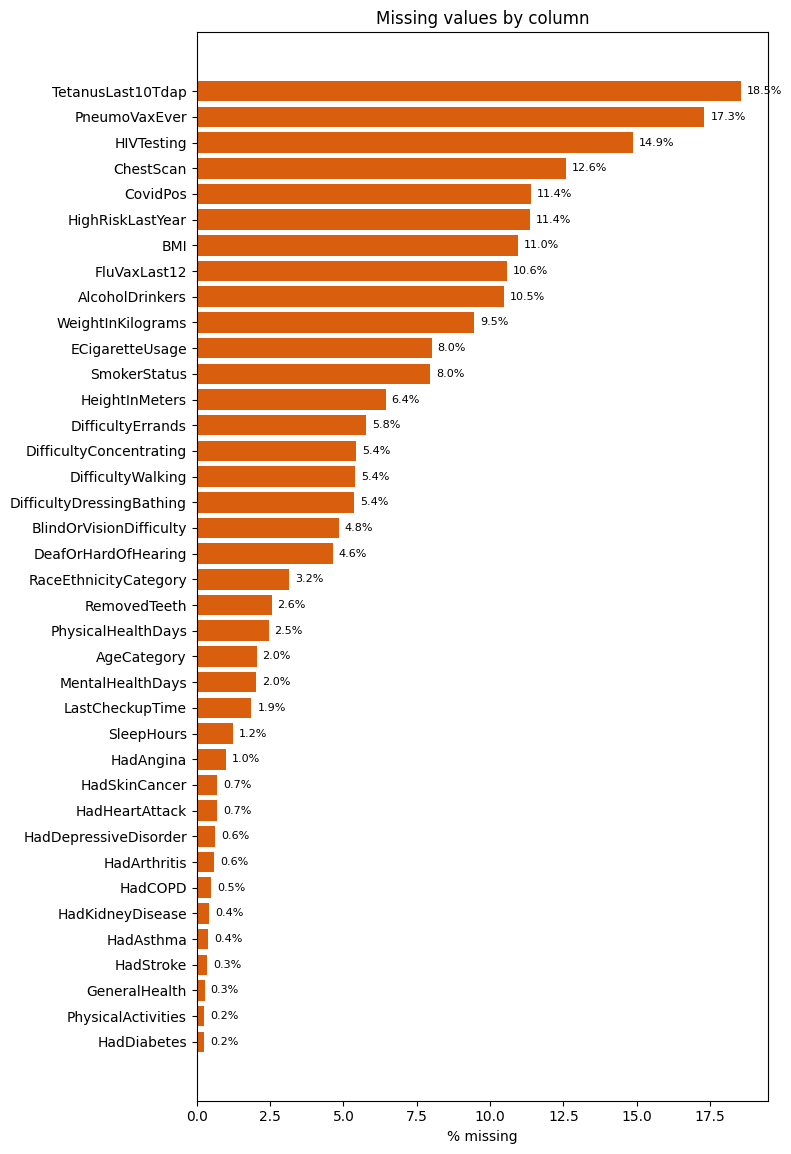


--- 2. Row-level missingness ---
Rows with no missing values : 246,022 (55.3%)
Rows with >=1 missing value : 199,110 (44.7%)
Mean missing values per row : 2.03  (max 38)


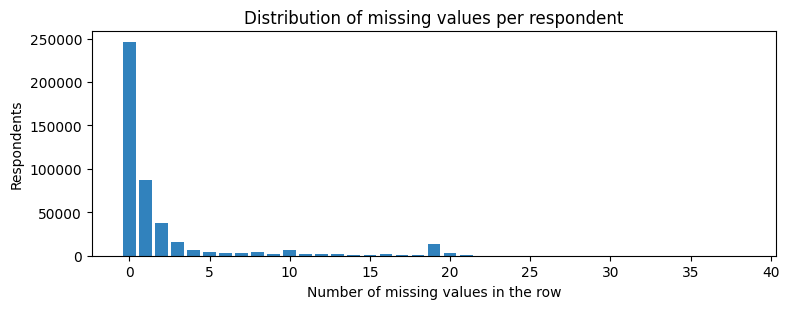


--- 3. Missingness patterns ---


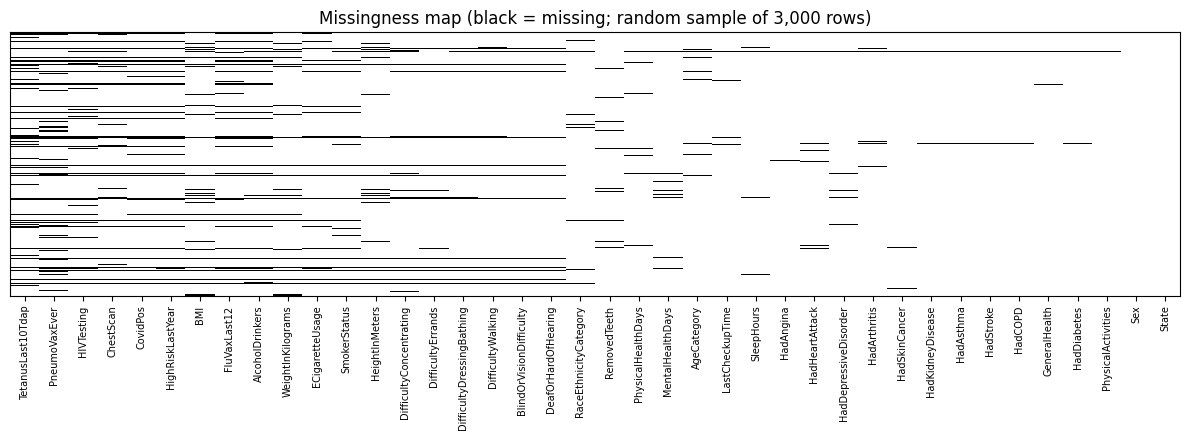

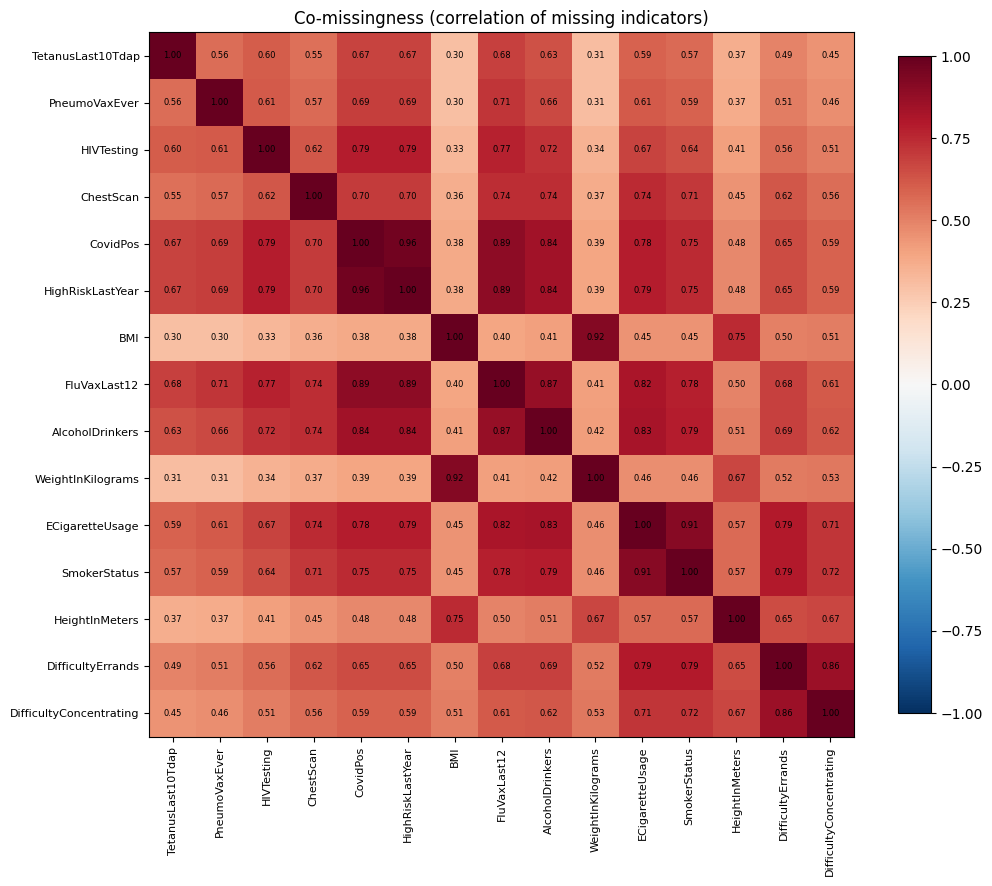


--- 4. Disguised missing values ---


'None found.'


--- 5. Missingness by demographic group ---

=== Sex ===  chi-square = 240.1, dof = 1, p = 3.83e-54, Cramér's V = 0.023
(0 rows have Sex itself missing)


,n,% rows incomplete,mean missing per row
Sex,,,
Female,235893,45.818,2.097
Male,209239,43.504,1.950



=== RaceEthnicityCategory ===  chi-square = 706.9, dof = 4, p = 1.13e-151, Cramér's V = 0.040
(14,057 rows have RaceEthnicityCategory itself missing)


,n,% rows incomplete,mean missing per row
RaceEthnicityCategory,,,
Hispanic,42917,47.410,2.332
"Other race only, Non-Hispanic",22713,46.264,2.413
"Black only, Non-Hispanic",35446,45.466,2.576
"White only, Non-Hispanic",320421,41.847,1.767
"Multiracial, Non-Hispanic",9578,41.731,1.751


... (5 outputs left out)


=== RaceEthnicityCategory ===


,n (with_nans),share (with_nans),prevalence (with_nans),n (no_nans),share (no_nans),prevalence (no_nans),% retained,share change (pts)
RaceEthnicityCategory,,,,,,,,
Hispanic,42917,0.100,0.038,22570,0.092,0.038,52.590,-0.782
"Other race only, Non-Hispanic",22713,0.053,0.046,12205,0.050,0.048,53.736,-0.308
"Black only, Non-Hispanic",35446,0.082,0.048,19330,0.079,0.046,54.534,-0.366
"White only, Non-Hispanic",320421,0.743,0.061,186336,0.757,0.058,58.153,1.409
"Multiracial, Non-Hispanic",9578,0.022,0.062,5581,0.023,0.061,58.269,0.047



=== AgeCategory ===


,n (with_nans),share (with_nans),prevalence (with_nans),n (no_nans),share (no_nans),prevalence (no_nans),% retained,share change (pts)
AgeCategory,,,,,,,,
Age 18 to 24,26941,0.062,0.005,13122,0.053,0.004,48.706,-0.845
Age 80 or older,36251,0.083,0.141,17816,0.072,0.136,49.146,-1.072
Age 25 to 29,21990,0.050,0.005,11109,0.045,0.004,50.518,-0.528
Age 30 to 34,25807,0.059,0.007,13346,0.054,0.007,51.715,-0.494
Age 35 to 39,28526,0.065,0.011,15614,0.063,0.010,54.736,-0.195
Age 75 to 79,32518,0.075,0.118,18136,0.074,0.114,55.772,-0.086
Age 40 to 44,29942,0.069,0.015,16973,0.069,0.013,56.686,0.032
Age 45 to 49,28531,0.065,0.026,16753,0.068,0.025,58.719,0.267
Age 50 to 54,33644,0.077,0.037,19913,0.081,0.035,59.187,0.378


In [1]:
"""
Missing-value assessment for the 2022 Indicators of Heart Disease dataset (CDC BRFSS).

Works on Kaggle (finds the files under /kaggle/input) or locally.
Paste it into a notebook cell, or run it as a script.

What it checks
  1. Column-level missingness (count, %, and a bar chart)
  2. Row-level missingness (how many values each respondent is missing)
  3. Missingness map and co-missingness (which columns go missing together)
  4. Disguised missing values (blank strings, "Unknown", "Refused", ...)
  5. Missingness by demographic group, with chi-square tests
  6. How complete-case filtering (with_nans -> no_nans) changes group composition
     and heart-attack prevalence, which matters for the fairness analysis
"""

import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# ---- Configuration ----------------------------------------------------------
SEARCH_DIRS = ["/kaggle/input", "."]
WITH_NANS   = "heart_2022_with_nans.csv"   # raw file: the one with missing values
NO_NANS     = "heart_2022_no_nans.csv"     # complete-case file used for modelling
TARGET      = "HadHeartAttack"
GROUP_COLS  = ["Sex", "RaceEthnicityCategory", "AgeCategory"]
DISGUISED   = {"", " ", "na", "n/a", "nan", "none", "null", "unknown",
               "refused", "don't know", "dont know", "not sure", "?", "-"}
TOP_N_COLS  = 15     # columns shown in the co-missingness heatmap

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.3f}".format)


def find_file(name):
    for d in SEARCH_DIRS:
        hits = sorted(glob.glob(os.path.join(d, "**", name), recursive=True))
        if hits:
            return hits[0]
    return None


def show(obj):
    """display() in notebooks, print() in scripts."""
    try:
        display(obj)  # noqa: F821
    except NameError:
        print(obj)


# ---- 1. Column-level missingness ---------------------------------------------
def column_missingness(df):
    miss = df.isna().sum()
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": miss,
        "missing %": 100 * miss / len(df),
        "unique (non-null)": df.nunique(),
    }).sort_values("missing %", ascending=False)
    return out


def plot_column_missingness(col_table, title="Missing values by column"):
    t = col_table[col_table["missing"] > 0]
    if t.empty:
        print("No missing values in any column.")
        return
    fig, ax = plt.subplots(figsize=(8, 0.28 * len(t) + 1))
    ax.barh(t.index, t["missing %"], color="#d95f0e")
    ax.invert_yaxis()
    ax.set_xlabel("% missing")
    ax.set_title(title)
    for y, v in enumerate(t["missing %"]):
        ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()


# ---- 2. Row-level missingness ------------------------------------------------
def row_missingness(df):
    per_row = df.isna().sum(axis=1)
    print(f"Rows with no missing values : {(per_row == 0).sum():,} ({(per_row == 0).mean():.1%})")
    print(f"Rows with >=1 missing value : {(per_row > 0).sum():,} ({(per_row > 0).mean():.1%})")
    print(f"Mean missing values per row : {per_row.mean():.2f}  (max {per_row.max()})")

    dist = per_row.value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(dist.index, dist.values, color="#3182bd")
    ax.set_xlabel("Number of missing values in the row")
    ax.set_ylabel("Respondents")
    ax.set_title("Distribution of missing values per respondent")
    plt.tight_layout()
    plt.show()
    return per_row


# ---- 3. Missingness map and co-missingness -------------------------------------
def plot_missing_map(df, sample=3000, seed=0):
    s = df.sample(min(sample, len(df)), random_state=seed)
    s = s[s.isna().sum().sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.imshow(s.isna().values, aspect="auto", interpolation="nearest", cmap="Greys")
    ax.set_xticks(range(s.shape[1]))
    ax.set_xticklabels(s.columns, rotation=90, fontsize=7)
    ax.set_yticks([])
    ax.set_title(f"Missingness map (black = missing; random sample of {len(s):,} rows)")
    plt.tight_layout()
    plt.show()


def plot_co_missingness(df, top_n=TOP_N_COLS):
    """Correlation of missingness indicators: do columns tend to be missing together?"""
    cols = df.isna().sum().sort_values(ascending=False)
    cols = cols[cols > 0].index[:top_n]
    if len(cols) < 2:
        print("Fewer than two columns with missing values; skipping co-missingness.")
        return None
    corr = df[cols].isna().astype(int).corr()
    fig, ax = plt.subplots(figsize=(0.5 * len(cols) + 3, 0.5 * len(cols) + 2))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=90, fontsize=8)
    ax.set_yticks(range(len(cols)))
    ax.set_yticklabels(cols, fontsize=8)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title("Co-missingness (correlation of missing indicators)")
    plt.tight_layout()
    plt.show()
    return corr


# ---- 4. Disguised missing values -----------------------------------------------
def disguised_missing(df):
    rows = []
    for col in df.select_dtypes(exclude="number").columns:
        vals = df[col].dropna().astype(str).str.strip().str.lower()
        hits = vals[vals.isin(DISGUISED)]
        if len(hits):
            rows.append({"column": col, "count": len(hits),
                         "%": 100 * len(hits) / len(df),
                         "values found": sorted(hits.unique())})
    for col in df.select_dtypes(include="number").columns:  # sentinel codes like 77/99/999
        for code in (77, 88, 99, 777, 999, -1):
            n = int((df[col] == code).sum())
            if n and n > 0.01 * df[col].notna().sum():
                rows.append({"column": col, "count": n, "%": 100 * n / len(df),
                             "values found": [f"possible sentinel {code}"]})
    return pd.DataFrame(rows) if rows else pd.DataFrame(columns=["column", "count", "%", "values found"])


# ---- 5. Missingness by demographic group ---------------------------------------
def missingness_by_group(df, group_col):
    """Share of rows with >=1 missing value and mean missing count, per group.
    Also runs a chi-square test: is 'row incomplete' independent of the group?"""
    d = df.dropna(subset=[group_col])
    incomplete = d.drop(columns=[group_col]).isna().any(axis=1)
    t = pd.DataFrame({
        "n": d.groupby(group_col).size(),
        "% rows incomplete": 100 * incomplete.groupby(d[group_col]).mean(),
        "mean missing per row": d.drop(columns=[group_col]).isna().sum(axis=1).groupby(d[group_col]).mean(),
    })
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(d[group_col], incomplete))
    n = len(d)
    cramers_v = np.sqrt(chi2 / (n * (min(pd.crosstab(d[group_col], incomplete).shape) - 1)))
    print(f"\n=== {group_col} ===  chi-square = {chi2:,.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}")
    print(f"({df[group_col].isna().sum():,} rows have {group_col} itself missing)")
    return t.sort_values("% rows incomplete", ascending=False)


def column_missingness_by_group(df, group_col, top_n=10):
    """% missing for the most-missing columns, broken down by group."""
    cols = df.isna().mean().sort_values(ascending=False)
    cols = [c for c in cols[cols > 0].index if c != group_col][:top_n]
    return (100 * df[cols].isna().groupby(df[group_col]).mean()).T


def target_missingness(df, target=TARGET):
    """Is heart-attack prevalence different among incomplete rows? (MCAR check on the outcome)"""
    d = df.dropna(subset=[target])
    incomplete = d.drop(columns=[target]).isna().any(axis=1)
    rate = (d[target].astype(str).str.lower() == "yes").groupby(incomplete).mean()
    chi2, p, _, _ = chi2_contingency(pd.crosstab(incomplete, d[target]))
    print(f"\nHeart-attack prevalence | complete rows: {rate.get(False, np.nan):.3%}"
          f"  | incomplete rows: {rate.get(True, np.nan):.3%}  (chi-square p = {p:.2e})")
    print(f"({df[target].isna().sum():,} rows have {target} itself missing)")


# ---- 6. Effect of complete-case filtering ----------------------------------------
def complete_case_shift(raw, clean, group_col, target=TARGET):
    """Compare group shares and prevalence before and after dropping incomplete rows."""
    def summary(d):
        known = d[d[target].notna()]                      # prevalence among known outcomes only
        yes = known[target].astype(str).str.lower() == "yes"
        return pd.DataFrame({"n": d.groupby(group_col).size(),
                             "share": d[group_col].value_counts(normalize=True),
                             "prevalence": yes.groupby(known[group_col]).mean()})
    a, b = summary(raw.dropna(subset=[group_col])), summary(clean)
    out = a.join(b, lsuffix=" (with_nans)", rsuffix=" (no_nans)")
    out["% retained"] = 100 * out["n (no_nans)"] / out["n (with_nans)"]
    out["share change (pts)"] = 100 * (out["share (no_nans)"] - out["share (with_nans)"])
    return out.sort_values("% retained")


# ---- Run -------------------------------------------------------------------------
def main():
    path_raw, path_clean = find_file(WITH_NANS), find_file(NO_NANS)
    print("with_nans file:", path_raw)
    print("no_nans file  :", path_clean)

    # The no_nans file should have none; confirm it
    if path_clean:
        clean = pd.read_csv(path_clean)
        print(f"\nno_nans file: {clean.shape}, total missing = {int(clean.isna().sum().sum())}")
        dm = disguised_missing(clean)
        print("Disguised missing values in no_nans file:" if len(dm) else "No disguised missing values in no_nans file.")
        if len(dm):
            show(dm)
    else:
        clean = None

    if path_raw is None:
        print("\nwith_nans file not found. Attach the full dataset to assess missingness in the raw data.")
    else:
        raw = pd.read_csv(path_raw)
        print(f"\nwith_nans file: {raw.shape}, total missing cells = {int(raw.isna().sum().sum()):,} "
              f"({raw.isna().mean().mean():.1%} of all cells)")

        print("\n--- 1. Column-level missingness ---")
        col_table = column_missingness(raw)
        show(col_table)
        plot_column_missingness(col_table)

        print("\n--- 2. Row-level missingness ---")
        row_missingness(raw)

        print("\n--- 3. Missingness patterns ---")
        plot_missing_map(raw)
        plot_co_missingness(raw)

        print("\n--- 4. Disguised missing values ---")
        dm = disguised_missing(raw)
        show(dm if len(dm) else "None found.")

        print("\n--- 5. Missingness by demographic group ---")
        for g in GROUP_COLS:
            show(missingness_by_group(raw, g))
        show(column_missingness_by_group(raw, "RaceEthnicityCategory"))
        target_missingness(raw)

        if clean is not None:
            print("\n--- 6. Effect of complete-case filtering (with_nans -> no_nans) ---")
            print(f"Rows retained overall: {len(clean):,} of {len(raw):,} ({len(clean) / len(raw):.1%})")
            for g in GROUP_COLS:
                print(f"\n=== {g} ===")
                show(complete_case_shift(raw, clean, g))


main()

Loaded /kaggle/input/datasets/kamilpytlak/personal-key-indicators-of-heart-disease/2022/heart_2022_no_nans.csv: (246022, 40)
Heart-attack prevalence: 5.46%

Categorical predictors:


,levels,categories
Sex,2,"Female, Male"
HadStroke,2,"No, Yes"
HadAngina,2,"No, Yes"
PhysicalActivities,2,"Yes, No"
HadDepressiveDisorder,2,"No, Yes"
HadCOPD,2,"No, Yes"
HadSkinCancer,2,"No, Yes"
HadAsthma,2,"No, Yes"
HadKidneyDisease,2,"No, Yes"
HadArthritis,2,"No, Yes"



Fitting encoder on training data...

Predictors: 38 original -> 68 encoded
X_train (172215, 68) | X_test (73807, 68)

Encoding dictionary:


,Original variable,Type,Encoded as,Reference (0)
0,PhysicalHealthDays,numeric,PhysicalHealthDays,
1,MentalHealthDays,numeric,MentalHealthDays,
2,SleepHours,numeric,SleepHours,
3,HeightInMeters,numeric,HeightInMeters,
4,WeightInKilograms,numeric,WeightInKilograms,
5,BMI,numeric,BMI,
6,Sex,binary,Sex_Male (1 = Male),other level
7,PhysicalActivities,binary,PhysicalActivities (1 = Yes),other level
8,HadAngina,binary,HadAngina (1 = Yes),other level
9,HadStroke,binary,HadStroke (1 = Yes),other level


Validation: all checks passed ✔

Encoded data (first rows):


,PhysicalHealthDays,MentalHealthDays,SleepHours,HeightInMeters,WeightInKilograms,BMI,Sex_Male,PhysicalActivities,HadAngina,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,DeafOrHardOfHearing,BlindOrVisionDifficulty,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,ChestScan,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,HighRiskLastYear,GeneralHealth_Very_good,GeneralHealth_Good,GeneralHealth_Fair,GeneralHealth_Poor,LastCheckupTime_Within_past_2_years,LastCheckupTime_Within_past_5_years,LastCheckupTime_5_or_more_years_ago,RemovedTeeth_1_to_5,RemovedTeeth_6_or_more_but_not_all,RemovedTeeth_All,HadDiabetes_Yes,HadDiabetes_No_pre_diabetes_or_borderline_diabetes,HadDiabetes_Yes_but_only_during_pregnancy,SmokerStatus_Former_smoker,SmokerStatus_Current_smoker_now_smokes_every_day,SmokerStatus_Current_smoker_now_smokes_some_days,ECigaretteUsage_Not_at_all,ECigaretteUsage_Use_them_some_days,ECigaretteUsage_Use_them_every_day,RaceEthnicityCategory_Hispanic,RaceEthnicityCategory_Black_only_Non_Hispanic,RaceEthnicityCategory_Other_race_only_Non_Hispanic,RaceEthnicityCategory_Multiracial_Non_Hispanic,AgeCategory_Age_25_to_29,AgeCategory_Age_30_to_34,AgeCategory_Age_35_to_39,AgeCategory_Age_40_to_44,AgeCategory_Age_45_to_49,AgeCategory_Age_50_to_54,AgeCategory_Age_55_to_59,AgeCategory_Age_60_to_64,AgeCategory_Age_65_to_69,AgeCategory_Age_70_to_74,AgeCategory_Age_75_to_79,AgeCategory_Age_80_or_older,TetanusLast10Tdap_Yes_received_tetanus_shot_but_not_sure_w,TetanusLast10Tdap_Yes_received_Tdap,TetanusLast10Tdap_Yes_received_tetanus_shot_but_not_Tdap,CovidPos_Yes,CovidPos_Tested_positive_using_home_test_without
0,4.000,0.000,9.000,1.600,71.670,27.990,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0
1,0.000,0.000,6.000,1.780,95.250,30.130,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
2,0.000,0.000,8.000,1.850,108.860,31.660,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0



Heart-attack prevalence by encoded predictor:


,Variable,n,Prevalence,Reference prevalence,Difference vs reference
Dummy,,,,,
HadAngina,HadAngina,14953,0.453,0.029,0.424
HadStroke,HadStroke,10112,0.249,0.046,0.203
GeneralHealth_Poor,GeneralHealth,9430,0.215,0.014,0.200
RemovedTeeth_All,RemovedTeeth,13778,0.167,0.029,0.138
AgeCategory_Age_80_or_older,AgeCategory,17816,0.136,0.004,0.132
...,...,...,...,...,...
AlcoholDrinkers,AlcoholDrinkers,135307,0.039,0.073,-0.034
LastCheckupTime_Within_past_2_years,LastCheckupTime,23227,0.025,0.063,-0.037
LastCheckupTime_Within_past_5_years,LastCheckupTime,13744,0.020,0.063,-0.043


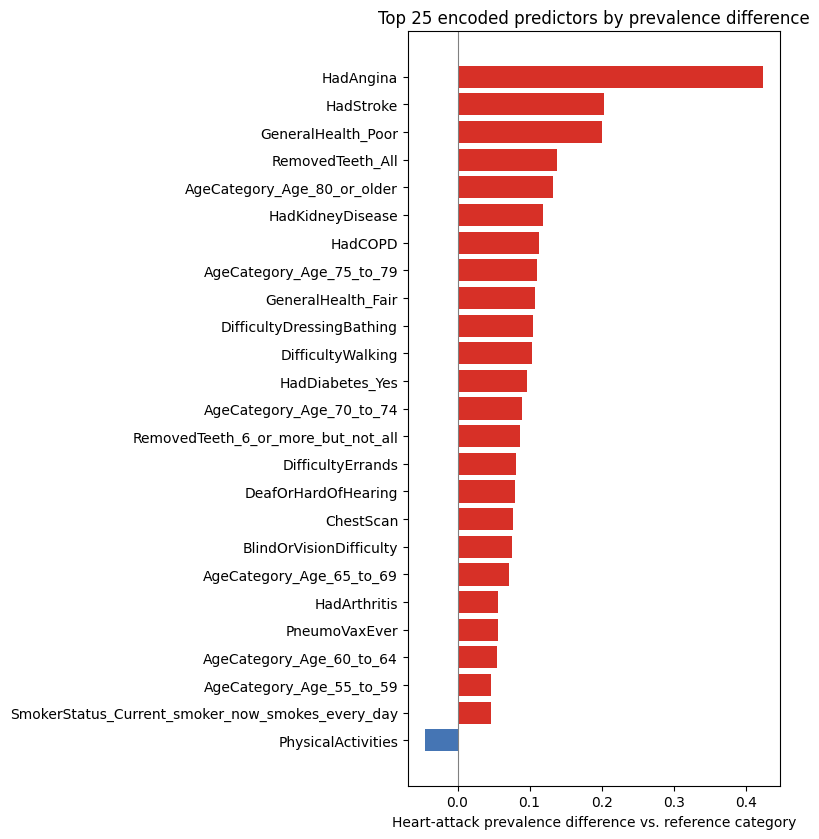


Saved encoded dataset (69 columns) to heart_2022_encoded.csv


In [2]:
"""
Feature engineering for heart-attack prediction: dummy variables for the categorical predictors.
Dataset: Indicators of Heart Disease 2022 (CDC BRFSS), heart_2022_no_nans.csv

What it does
  1. Classifies every column as target, numeric, binary (Yes/No-type) or multi-category.
  2. Encodes the predictors:
       * binary columns     -> one 0/1 column (1 = "Yes", or 1 = "Male" for Sex)
       * multi-category     -> k-1 dummy columns, dropping a chosen, meaningful reference category
       * AgeCategory        -> dummies (default) or a single ordinal number
       * State              -> dropped by default (54 levels; optional dummies)
  3. Fits the encoding on training data only and applies the same columns to test data,
     so unseen or missing categories never break the pipeline.
  4. Validates the result and prints an encoding dictionary (original column -> dummies, reference).
  5. Shows how each dummy relates to heart attack (prevalence difference vs. the reference).
"""

import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# ---- Configuration ----------------------------------------------------------
SEARCH_DIRS   = ["/kaggle/input", "."]
DATA_FILE     = "heart_2022_no_nans.csv"
TARGET        = "HadHeartAttack"
DROP_COLUMNS  = ["State"]        # set to [] to dummy-encode State as well
AGE_ENCODING  = "dummies"        # "dummies" or "ordinal" (lower bound of the age band: 18, 25, ... 80)
DROP_REFERENCE = True            # True: k-1 dummies (needed for regression; fine for trees)
                                 # False: keep all k dummies (tree models only)
MAX_LEVELS    = 60               # safety limit: columns with more levels are not dummy-encoded
OUTPUT_CSV    = "heart_2022_encoded.csv"

# Reference (baseline) category for each multi-category variable.
# Matching is exact first, then by case-insensitive prefix, so long BRFSS labels need only their start.
# If a reference is not found, the most frequent category is used and a note is printed.
REFERENCE = {
    "Sex":                   "Female",
    "RaceEthnicityCategory": "White only",
    "AgeCategory":           "Age 18 to 24",
    "GeneralHealth":         "Excellent",
    "LastCheckupTime":       "Within past year",
    "RemovedTeeth":          "None of them",
    "SmokerStatus":          "Never smoked",
    "ECigaretteUsage":       "Never used",
    "HadDiabetes":           "No",
    "TetanusLast10Tdap":     "No",
    "CovidPos":              "No",
    "State":                 None,        # None -> most frequent category
}
POSITIVE_LABELS = {"yes", "male", "true", "1", "y"}   # value coded as 1 in binary columns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:.3f}".format)


def show(obj):
    try:
        display(obj)  # noqa: F821
    except NameError:
        print(obj)


def find_file(name):
    for d in SEARCH_DIRS:
        hits = sorted(glob.glob(os.path.join(d, "**", name), recursive=True))
        if hits:
            return hits[0]
    return None


def safe_name(text, max_len=40):
    """Short, column-name-friendly version of a category label."""
    s = str(text).split("(")[0].strip()
    for a, b in [(",", ""), (" - ", "_"), (" ", "_"), ("/", "_"), ("'", ""), ("-", "_")]:
        s = s.replace(a, b)
    return s[:max_len].rstrip("_")


# ---- The encoder -------------------------------------------------------------
class DummyEncoder:
    """Learns categories on training data; applies identical dummy columns to any later data."""

    def __init__(self, reference=None, drop_reference=True, age_encoding="dummies",
                 drop_columns=(), max_levels=60, target=TARGET):
        self.reference = reference or {}
        self.drop_reference = drop_reference
        self.age_encoding = age_encoding
        self.drop_columns = list(drop_columns)
        self.max_levels = max_levels
        self.target = target

    # -- helpers
    def _pick_reference(self, col, levels, counts):
        wanted = self.reference.get(col)
        if wanted is not None:
            for lvl in levels:                          # exact match first ("No" vs "No, pre-diabetes...")
                if str(lvl).strip().lower() == str(wanted).strip().lower():
                    return lvl
            for lvl in levels:                          # then prefix match for long BRFSS labels
                if str(lvl).lower().startswith(str(wanted).lower()):
                    return lvl
            print(f"  note: reference '{wanted}' not found in {col}; using most frequent level")
        return counts.idxmax()

    # -- fit
    def fit(self, df):
        X = df.drop(columns=[self.target, *self.drop_columns], errors="ignore")
        self.numeric_, self.binary_, self.multi_, self.skipped_ = [], {}, {}, []
        self.age_ordinal_ = False

        for col in X.columns:
            if pd.api.types.is_numeric_dtype(X[col]):
                self.numeric_.append(col)
                continue
            counts = X[col].value_counts()
            levels = list(counts.index)

            if col == "AgeCategory" and self.age_encoding == "ordinal":
                self.age_ordinal_ = True
                continue
            if len(levels) > self.max_levels:
                self.skipped_.append(col)
                continue
            if len(levels) == 2:
                pos = [l for l in levels if str(l).strip().lower() in POSITIVE_LABELS]
                positive = pos[0] if pos else sorted(levels)[-1]
                self.binary_[col] = positive
                continue

            ref = self._pick_reference(col, levels, counts)
            ordered = self._order_levels(col, levels)
            keep = [l for l in ordered if not (self.drop_reference and l == ref)]
            names, used = [], set()
            for l in keep:
                n = f"{col}_{safe_name(l)}"
                while n in used:                       # guarantee unique column names
                    n += "_"
                used.add(n); names.append(n)
            self.multi_[col] = {"reference": ref, "levels": keep, "names": names}
        return self

    @staticmethod
    def _order_levels(col, levels):
        """Natural order for age bands; frequency order otherwise."""
        if col == "AgeCategory":
            return sorted(levels, key=lambda s: int(pd.Series([s]).str.extract(r"(\d+)")[0].iloc[0]))
        return levels

    # -- transform
    def transform(self, df):
        out = pd.DataFrame(index=df.index)
        for col in self.numeric_:
            out[col] = df[col].astype(float)
        if self.age_ordinal_:
            out["AgeCategory"] = df["AgeCategory"].astype(str).str.extract(r"(\d+)")[0].astype(float)
        for col, positive in self.binary_.items():
            name = "Sex_Male" if col == "Sex" else col
            out[name] = (df[col] == positive).astype(np.uint8)
        for col, spec in self.multi_.items():
            for lvl, name in zip(spec["levels"], spec["names"]):
                out[name] = (df[col] == lvl).astype(np.uint8)
            unseen = ~df[col].isin(spec["levels"] + [spec["reference"]]) & df[col].notna()
            if unseen.any():
                print(f"  note: {unseen.sum()} rows in {col} have categories not seen in training "
                      f"(encoded as all zeros)")
        return out

    def fit_transform(self, df):
        return self.fit(df).transform(df)

    # -- documentation
    def encoding_table(self):
        rows = [{"Original variable": c, "Type": "numeric", "Encoded as": c, "Reference (0)": ""}
                for c in self.numeric_]
        if self.age_ordinal_:
            rows.append({"Original variable": "AgeCategory", "Type": "ordinal",
                         "Encoded as": "AgeCategory (lower bound of band)", "Reference (0)": ""})
        for c, pos in self.binary_.items():
            rows.append({"Original variable": c, "Type": "binary",
                         "Encoded as": f"{'Sex_Male' if c == 'Sex' else c} (1 = {pos})",
                         "Reference (0)": "other level"})
        for c, spec in self.multi_.items():
            rows.append({"Original variable": c, "Type": f"categorical ({len(spec['levels']) + self.drop_reference} levels)",
                         "Encoded as": ", ".join(spec["names"]),
                         "Reference (0)": spec["reference"] if self.drop_reference else "(none dropped)"})
        for c in self.skipped_:
            rows.append({"Original variable": c, "Type": f">{self.max_levels} levels",
                         "Encoded as": "NOT ENCODED", "Reference (0)": ""})
        for c in self.drop_columns:
            rows.append({"Original variable": c, "Type": "dropped", "Encoded as": "-", "Reference (0)": ""})
        return pd.DataFrame(rows)


# ---- Validation ----------------------------------------------------------------
def validate(X, enc, df):
    problems = []
    if X.isna().any().any():
        problems.append(f"missing values in: {list(X.columns[X.isna().any()])}")
    non_numeric = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    if non_numeric:
        problems.append(f"non-numeric columns: {non_numeric}")
    if len(X) != len(df):
        problems.append("row count changed")
    for col, spec in enc.multi_.items():            # each row belongs to at most one dummy per variable
        s = X[spec["names"]].sum(axis=1)
        limit = 1
        if (s > limit).any():
            problems.append(f"{col}: some rows have more than one dummy = 1")
        if not enc.drop_reference and (s != 1).any():
            problems.append(f"{col}: some rows have no dummy = 1")
    constant = [c for c in X.columns if X[c].nunique() <= 1]
    if constant:
        problems.append(f"constant columns (no information): {constant}")
    print("Validation:", "all checks passed ✔" if not problems else "")
    for p in problems:
        print("  ✘", p)


def dummy_effects(X, y, enc):
    """Heart-attack prevalence in each dummy's group vs. the reference group of the same variable."""
    rows = []
    for col, spec in enc.multi_.items():
        ref_mask = X[spec["names"]].sum(axis=1) == 0
        ref_rate = y[ref_mask].mean() if ref_mask.any() else np.nan
        for name in spec["names"]:
            m = X[name] == 1
            rows.append({"Dummy": name, "Variable": col, "n": int(m.sum()),
                         "Prevalence": y[m].mean(), "Reference prevalence": ref_rate,
                         "Difference vs reference": y[m].mean() - ref_rate})
    for col in enc.binary_:
        name = "Sex_Male" if col == "Sex" else col
        m = X[name] == 1
        rows.append({"Dummy": name, "Variable": col, "n": int(m.sum()), "Prevalence": y[m].mean(),
                     "Reference prevalence": y[~m].mean(), "Difference vs reference": y[m].mean() - y[~m].mean()})
    return pd.DataFrame(rows).sort_values("Difference vs reference", ascending=False).set_index("Dummy")


def plot_effects(effects, top=25):
    t = effects.reindex(effects["Difference vs reference"].abs().sort_values(ascending=False).index).head(top)
    t = t.sort_values("Difference vs reference")
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(t) + 1))
    ax.barh(t.index, t["Difference vs reference"],
            color=np.where(t["Difference vs reference"] > 0, "#d73027", "#4575b4"))
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel("Heart-attack prevalence difference vs. reference category")
    ax.set_title(f"Top {len(t)} encoded predictors by prevalence difference")
    plt.tight_layout()
    plt.show()


# ---- Run -------------------------------------------------------------------------
def main():
    path = find_file(DATA_FILE)
    if path is None:
        raise FileNotFoundError(f"{DATA_FILE} not found under {SEARCH_DIRS}")
    df = pd.read_csv(path)
    print(f"Loaded {path}: {df.shape}")

    # Target as 0/1
    y = (df[TARGET].astype(str).str.strip().str.lower() == "yes").astype(int)
    print(f"Heart-attack prevalence: {y.mean():.2%}\n")

    # Overview of the categorical predictors
    cats = [c for c in df.columns if c != TARGET and not pd.api.types.is_numeric_dtype(df[c])]
    overview = pd.DataFrame({"levels": [df[c].nunique() for c in cats],
                             "categories": [", ".join(map(str, df[c].value_counts().index[:6]))
                                            + (" ..." if df[c].nunique() > 6 else "") for c in cats]},
                            index=cats).sort_values("levels")
    print("Categorical predictors:")
    show(overview)

    # Split first, then fit the encoder on the training data only
    idx_train, idx_test = train_test_split(df.index, test_size=0.30, stratify=y, random_state=42)
    enc = DummyEncoder(reference=REFERENCE, drop_reference=DROP_REFERENCE, age_encoding=AGE_ENCODING,
                       drop_columns=DROP_COLUMNS, max_levels=MAX_LEVELS)
    print("\nFitting encoder on training data...")
    enc.fit(df.loc[idx_train])

    X_train = enc.transform(df.loc[idx_train])
    X_test  = enc.transform(df.loc[idx_test])
    y_train, y_test = y.loc[idx_train], y.loc[idx_test]
    assert list(X_train.columns) == list(X_test.columns), "train/test columns differ"

    print(f"\nPredictors: {df.shape[1] - 1 - len(DROP_COLUMNS)} original -> {X_train.shape[1]} encoded")
    print(f"X_train {X_train.shape} | X_test {X_test.shape}\n")

    print("Encoding dictionary:")
    show(enc.encoding_table())

    X_full = enc.transform(df)
    validate(X_full, enc, df)

    print("\nEncoded data (first rows):")
    show(X_full.head(3))

    effects = dummy_effects(X_full, y, enc)
    print("\nHeart-attack prevalence by encoded predictor:")
    show(effects)
    plot_effects(effects)

    X_full.assign(**{TARGET: y}).to_csv(OUTPUT_CSV, index=False)
    print(f"\nSaved encoded dataset ({X_full.shape[1] + 1} columns) to {OUTPUT_CSV}")

    return enc, X_train, X_test, y_train, y_test


enc, X_train, X_test, y_train, y_test = main()

In [3]:
# 4.2.3 Value Mapping
# Convert two-category columns in df_dummies to numeric values (True/Yes = 1, False/No = 0).
import numpy as np
import pandas as pd

# Step 1: identify columns in df_dummies with exactly two unique categories
# (text is compared case-insensitively, so 'Y', 'y' and 'n' count as two categories, not three)
def n_categories(series):
    if pd.api.types.is_numeric_dtype(series) and not pd.api.types.is_bool_dtype(series):
        return series.nunique()
    return series.dropna().astype(str).str.strip().str.lower().nunique()

two_category_columns = [col for col in df_dummies.columns if n_categories(df_dummies[col]) == 2]

# Step 2: mapping dictionary for common true/false-like categories
# (values are compared after stripping spaces and lower-casing, so 'Yes', 'YES' and ' yes' all match)
binary_mapping = {
    "yes": 1,  "no": 0,
    "true": 1, "false": 0,
    "1": 1,    "0": 0,
    "y": 1,    "n": 0,
}

# Step 3: apply the mapping to the identified columns
mapping_log = []
for col in two_category_columns:
    values = df_dummies[col]

    if pd.api.types.is_bool_dtype(values):
        # pd.get_dummies() returns Python booleans (True/False), not strings
        df_dummies[col] = values.astype(int)
        mapping_log.append((col, "boolean", "True -> 1, False -> 0"))
        continue

    normalised = values.astype(str).str.strip().str.lower()
    if set(normalised.unique()).issubset(binary_mapping):
        df_dummies[col] = normalised.map(binary_mapping).astype(int)
        mapping_log.append((col, "true/false-like", "yes/true/1/y -> 1, no/false/0/n -> 0"))
    else:
        # Non-standard categories (e.g. 'Female'/'Male'): use a fixed alphabetical order
        # so the coding is reproducible and does not depend on which value appears first
        low, high = sorted(values.dropna().unique(), key=str)[:2]
        df_dummies[col] = values.map({low: 0, high: 1}).astype(int)
        mapping_log.append((col, "custom", f"{low} -> 0, {high} -> 1"))

# Step 4: verify and document the result
mapping_summary = pd.DataFrame(mapping_log, columns=["Column", "Mapping type", "Coding"])
print(mapping_summary.to_string(index=False))

not_binary = [c for c in two_category_columns if not set(df_dummies[c].unique()) <= {0, 1}]
print("\nAll mapped columns contain only 0 and 1:", not not_binary)
print("Columns still non-numeric:",
      [c for c in df_dummies.columns if not pd.api.types.is_numeric_dtype(df_dummies[c])] or "none")

NameError: name 'df_dummies' is not defined

In [ ]:
import glob
import pandas as pd

# Load the data from the attached Kaggle dataset
path = glob.glob("/kaggle/input/**/heart_2022_no_nans.csv", recursive=True)[0]
HD_Data = pd.read_csv(path)
print("Loaded:", path, HD_Data.shape)

# Age category pre-processing: Above 50 / Below 50
above_50 = ["Age 50 to 54", "Age 55 to 59", "Age 60 to 64", "Age 65 to 69",
            "Age 70 to 74", "Age 75 to 79", "Age 80 or older"]
HD_Data["AgeCategory"] = HD_Data["AgeCategory"].apply(
    lambda a: "Above 50" if a in above_50 else "Below 50")

# Dummy variables
df = HD_Data.copy()
df1 = df.drop(columns=["RaceEthnicityCategory"])
df2 = df["RaceEthnicityCategory"]
columns_to_encode = [col for col in df1.columns if df1[col].nunique() < 6]

df_races = pd.get_dummies(df2, drop_first=False)
df_other_cols = pd.get_dummies(df1, columns=columns_to_encode, drop_first=True)
df_dummies = pd.concat([df_other_cols, df_races], axis=1)
df_dummies = df_dummies.drop(columns=["Other race only, Non-Hispanic"])

print("df_dummies:", df_dummies.shape)

In [ ]:
# 4.2.3 Value Mapping
# Convert two-category columns in df_dummies to numeric values (True/Yes = 1, False/No = 0).
import numpy as np
import pandas as pd

# Step 1: identify columns in df_dummies with exactly two unique categories
# (text is compared case-insensitively, so 'Y', 'y' and 'n' count as two categories, not three)
def n_categories(series):
    if pd.api.types.is_numeric_dtype(series) and not pd.api.types.is_bool_dtype(series):
        return series.nunique()
    return series.dropna().astype(str).str.strip().str.lower().nunique()

two_category_columns = [col for col in df_dummies.columns if n_categories(df_dummies[col]) == 2]

# Step 2: mapping dictionary for common true/false-like categories
# (values are compared after stripping spaces and lower-casing, so 'Yes', 'YES' and ' yes' all match)
binary_mapping = {
    "yes": 1,  "no": 0,
    "true": 1, "false": 0,
    "1": 1,    "0": 0,
    "y": 1,    "n": 0,
}

# Step 3: apply the mapping to the identified columns
mapping_log = []
for col in two_category_columns:
    values = df_dummies[col]

    if pd.api.types.is_bool_dtype(values):
        # pd.get_dummies() returns Python booleans (True/False), not strings
        df_dummies[col] = values.astype(int)
        mapping_log.append((col, "boolean", "True -> 1, False -> 0"))
        continue

    normalised = values.astype(str).str.strip().str.lower()
    if set(normalised.unique()).issubset(binary_mapping):
        df_dummies[col] = normalised.map(binary_mapping).astype(int)
        mapping_log.append((col, "true/false-like", "yes/true/1/y -> 1, no/false/0/n -> 0"))
    else:
        # Non-standard categories (e.g. 'Female'/'Male'): use a fixed alphabetical order
        # so the coding is reproducible and does not depend on which value appears first
        low, high = sorted(values.dropna().unique(), key=str)[:2]
        df_dummies[col] = values.map({low: 0, high: 1}).astype(int)
        mapping_log.append((col, "custom", f"{low} -> 0, {high} -> 1"))

# Step 4: verify and document the result
mapping_summary = pd.DataFrame(mapping_log, columns=["Column", "Mapping type", "Coding"])
print(mapping_summary.to_string(index=False))

not_binary = [c for c in two_category_columns if not set(df_dummies[c].unique()) <= {0, 1}]
print("\nAll mapped columns contain only 0 and 1:", not not_binary)
print("Columns still non-numeric:",
      [c for c in df_dummies.columns if not pd.api.types.is_numeric_dtype(df_dummies[c])] or "none")

In [ ]:
# Correlations: Figure 5 – correlation matrix heatmap of the features
# Run after the sampling step (needs sampled_df with HadHeartAttack_Yes as 0/1).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

TARGET       = "HadHeartAttack_Yes"
EXCLUDE      = ["State"]     # non-numeric / not used as a predictor
STRONG       = 0.5           # |r| above this is reported as a strong correlation
ANNOTATE_MAX = 25            # write r values in the cells only if the matrix is this small or smaller

# Correlation is unaffected by scaling, so the (un-standardised) sampled data gives the same matrix
data = sampled_df.drop(columns=EXCLUDE, errors="ignore")
data = data.select_dtypes(include=["number", "bool"]).astype(float)

# Drop constant columns (their correlation is undefined)
constant = [c for c in data.columns if data[c].nunique() <= 1]
if constant:
    print("Dropped constant columns:", constant)
    data = data.drop(columns=constant)

corr = data.corr(method="pearson")   # for 0/1 columns this equals the phi coefficient
print(f"Correlation matrix: {corr.shape[0]} features")


# Shorter labels so the heatmap is readable
def short_label(name, max_len=28):
    for a, b in [(", Non-Hispanic", ""), (" only", ""), ("_Yes", ""), ("Category", ""),
                 ("Difficulty", "Diff. "), ("  ", " ")]:
        name = name.replace(a, b)
    return name if len(name) <= max_len else name[:max_len - 1] + "…"

labels = [short_label(c) for c in corr.columns]

# ---------------------------------------------------------------------------
# Figure 5: correlation matrix heatmap (lower triangle; the upper half is a mirror image)
# ---------------------------------------------------------------------------
n = len(corr)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
size = max(8, 0.32 * n)
fig, ax = plt.subplots(figsize=(size, size * 0.85))
sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=n <= ANNOTATE_MAX, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.3, linecolor="white", square=True,
            xticklabels=labels, yticklabels=labels,
            cbar_kws={"shrink": 0.6, "label": "Pearson correlation (r)"}, ax=ax)
ax.tick_params(axis="x", labelsize=7, rotation=90)
ax.tick_params(axis="y", labelsize=7, rotation=0)
ax.set_title("Figure 5. Correlation matrix heatmap of features", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig("figure5_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Strongest correlations between pairs of features (to describe the heatmap in the text)
# ---------------------------------------------------------------------------
pairs = (corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1))
             .stack()
             .rename("r")
             .reset_index()
             .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"}))
pairs["|r|"] = pairs["r"].abs()
pairs = pairs.sort_values("|r|", ascending=False)

print(f"\nTop 15 correlated feature pairs:")
print(pairs.head(15).to_string(index=False, float_format="{:.3f}".format))

strong = pairs[pairs["|r|"] >= STRONG]
print(f"\n{len(strong)} pairs with |r| >= {STRONG} (possible redundancy / multicollinearity)")
print(f"Median |r| across all {len(pairs):,} pairs: {pairs['|r|'].median():.3f}")

# ---------------------------------------------------------------------------
# Correlation of each feature with the target (heart attack)
# ---------------------------------------------------------------------------
if TARGET in corr.columns:
    with_target = corr[TARGET].drop(TARGET).sort_values()
    print(f"\nStrongest positive correlations with {TARGET}:")
    print(with_target.tail(10)[::-1].round(3).to_string())
    print(f"\nStrongest negative correlations with {TARGET}:")
    print(with_target.head(10).round(3).to_string())

    fig, ax = plt.subplots(figsize=(8, 0.22 * len(with_target) + 1))
    ax.barh([short_label(c) for c in with_target.index], with_target.values,
            color=np.where(with_target.values > 0, "#d73027", "#4575b4"))
    ax.axvline(0, color="grey", lw=0.8)
    ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel("Pearson correlation with heart attack (r)")
    ax.set_title("Correlation of each feature with heart attack")
    plt.tight_layout()
    plt.savefig("figure6_correlation_with_target.png", dpi=300, bbox_inches="tight")
    plt.show()

In [ ]:
# Setup: rebuild everything the later cells need (HD_Data -> df_dummies -> HD_New_Data -> sampled_df)
import glob
import pandas as pd

# 1. Load the data
path = glob.glob("/kaggle/input/**/heart_2022_no_nans.csv", recursive=True)[0]
HD_Data = pd.read_csv(path)

# 2. Age category pre-processing
above_50 = ["Age 50 to 54", "Age 55 to 59", "Age 60 to 64", "Age 65 to 69",
            "Age 70 to 74", "Age 75 to 79", "Age 80 or older"]
HD_Data["AgeCategory"] = HD_Data["AgeCategory"].apply(
    lambda a: "Above 50" if a in above_50 else "Below 50")

# 3. Dummy variables
df = HD_Data.copy()
df1 = df.drop(columns=["RaceEthnicityCategory"])
df2 = df["RaceEthnicityCategory"]
columns_to_encode = [c for c in df1.columns if df1[c].nunique() < 6]
df_dummies = pd.concat([pd.get_dummies(df1, columns=columns_to_encode, drop_first=True),
                        pd.get_dummies(df2, drop_first=False)], axis=1)
df_dummies = df_dummies.drop(columns=["Other race only, Non-Hispanic"])

# 4. Value mapping (True/Yes = 1, False/No = 0)
binary_mapping = {"yes": 1, "no": 0, "true": 1, "false": 0, "1": 1, "0": 0, "y": 1, "n": 0}
for col in df_dummies.columns:
    s = df_dummies[col]
    if pd.api.types.is_bool_dtype(s):
        df_dummies[col] = s.astype(int)
    elif not pd.api.types.is_numeric_dtype(s) and s.str.strip().str.lower().nunique() == 2:
        norm = s.str.strip().str.lower()
        if set(norm.unique()) <= set(binary_mapping):
            df_dummies[col] = norm.map(binary_mapping)
        else:
            low, high = sorted(s.unique())
            df_dummies[col] = s.map({low: 0, high: 1})
HD_New_Data = df_dummies.copy()

# 5. Balanced sample: 12,500 cases per class, without replacement where possible
TARGET, per_class = "HadHeartAttack_Yes", 12500
sampled_df = (pd.concat([g.sample(n=per_class, replace=len(g) < per_class, random_state=42)
                         for _, g in HD_New_Data.groupby(TARGET)])
                .sample(frac=1, random_state=42)
                .reset_index(drop=True))

print("Loaded:", path)
print("HD_New_Data:", HD_New_Data.shape, "| sampled_df:", sampled_df.shape)
print(sampled_df[TARGET].value_counts())

In [ ]:
# Correlations: Figure 5 – correlation matrix heatmap of the features
# Run after the sampling step (needs sampled_df with HadHeartAttack_Yes as 0/1).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

TARGET       = "HadHeartAttack_Yes"
EXCLUDE      = ["State"]     # non-numeric / not used as a predictor
STRONG       = 0.5           # |r| above this is reported as a strong correlation
ANNOTATE_MAX = 25            # write r values in the cells only if the matrix is this small or smaller

# Correlation is unaffected by scaling, so the (un-standardised) sampled data gives the same matrix
data = sampled_df.drop(columns=EXCLUDE, errors="ignore")
data = data.select_dtypes(include=["number", "bool"]).astype(float)

# Drop constant columns (their correlation is undefined)
constant = [c for c in data.columns if data[c].nunique() <= 1]
if constant:
    print("Dropped constant columns:", constant)
    data = data.drop(columns=constant)

corr = data.corr(method="pearson")   # for 0/1 columns this equals the phi coefficient
print(f"Correlation matrix: {corr.shape[0]} features")


# Shorter labels so the heatmap is readable
def short_label(name, max_len=28):
    for a, b in [(", Non-Hispanic", ""), (" only", ""), ("_Yes", ""), ("Category", ""),
                 ("Difficulty", "Diff. "), ("  ", " ")]:
        name = name.replace(a, b)
    return name if len(name) <= max_len else name[:max_len - 1] + "…"

labels = [short_label(c) for c in corr.columns]

# ---------------------------------------------------------------------------
# Figure 5: correlation matrix heatmap (lower triangle; the upper half is a mirror image)
# ---------------------------------------------------------------------------
n = len(corr)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
size = max(8, 0.32 * n)
fig, ax = plt.subplots(figsize=(size, size * 0.85))
sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=n <= ANNOTATE_MAX, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.3, linecolor="white", square=True,
            xticklabels=labels, yticklabels=labels,
            cbar_kws={"shrink": 0.6, "label": "Pearson correlation (r)"}, ax=ax)
ax.tick_params(axis="x", labelsize=7, rotation=90)
ax.tick_params(axis="y", labelsize=7, rotation=0)
ax.set_title("Figure 5. Correlation matrix heatmap of features", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig("figure5_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Strongest correlations between pairs of features (to describe the heatmap in the text)
# ---------------------------------------------------------------------------
pairs = (corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1))
             .stack()
             .rename("r")
             .reset_index()
             .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"}))
pairs["|r|"] = pairs["r"].abs()
pairs = pairs.sort_values("|r|", ascending=False)

print(f"\nTop 15 correlated feature pairs:")
print(pairs.head(15).to_string(index=False, float_format="{:.3f}".format))

strong = pairs[pairs["|r|"] >= STRONG]
print(f"\n{len(strong)} pairs with |r| >= {STRONG} (possible redundancy / multicollinearity)")
print(f"Median |r| across all {len(pairs):,} pairs: {pairs['|r|'].median():.3f}")

# ---------------------------------------------------------------------------
# Correlation of each feature with the target (heart attack)
# ---------------------------------------------------------------------------
if TARGET in corr.columns:
    with_target = corr[TARGET].drop(TARGET).sort_values()
    print(f"\nStrongest positive correlations with {TARGET}:")
    print(with_target.tail(10)[::-1].round(3).to_string())
    print(f"\nStrongest negative correlations with {TARGET}:")
    print(with_target.head(10).round(3).to_string())

    fig, ax = plt.subplots(figsize=(8, 0.22 * len(with_target) + 1))
    ax.barh([short_label(c) for c in with_target.index], with_target.values,
            color=np.where(with_target.values > 0, "#d73027", "#4575b4"))
    ax.axvline(0, color="grey", lw=0.8)
    ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel("Pearson correlation with heart attack (r)")
    ax.set_title("Correlation of each feature with heart attack")
    plt.tight_layout()
    plt.savefig("figure6_correlation_with_target.png", dpi=300, bbox_inches="tight")
    plt.show()

In [ ]:
# 4.3.1 The Random Forest Classifier
# 4.3.1.1 RF Model Overall Performance  ->  Table 1 and Figure 7
# Needs sampled_df (the balanced sample of 25,000 cases). Run the setup cell first if it is missing.
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, make_scorer,
                             precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split

if "sampled_df" not in globals():
    raise NameError("sampled_df is not defined: run the setup/sampling cell first, then this cell.")

TARGET       = "HadHeartAttack_Yes"
TEST_SIZE    = 0.30
K            = 5
RANDOM_STATE = 42
RUN_TUNING   = True     # grid search over the three hyperparameters (a few minutes); False to skip

# ---------------------------------------------------------------------------
# Predictors and target
# (State is excluded, as before. Tree models do not need feature scaling, so the
#  unscaled 0/1 and numeric features are used directly.)
# ---------------------------------------------------------------------------
X = sampled_df.drop(columns=[TARGET, "State"], errors="ignore").astype(float)
y = sampled_df[TARGET].astype(int)

# 70% training / 30% testing, stratified so both sets keep the 50/50 class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Training set: {len(X_train):,} cases | Testing set: {len(X_test):,} cases | Features: {X.shape[1]}")

# Scorers: precision, recall and F1 are computed for the positive class (heart attack = 1)
scoring = {
    "accuracy":  "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall":    make_scorer(recall_score, pos_label=1),
    "f1":        make_scorer(f1_score, pos_label=1),
}
cv = StratifiedKFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)

# ---------------------------------------------------------------------------
# Hyperparameter tuning: n_estimators, criterion, min_samples_split (training data only)
# ---------------------------------------------------------------------------
best_params = {"n_estimators": 400, "criterion": "gini", "min_samples_split": 2}
if RUN_TUNING:
    param_grid = {
        "n_estimators":      [100, 200, 400],
        "criterion":         ["gini", "entropy"],
        "min_samples_split": [2, 5, 10],
    }
    t0 = time.time()
    grid = GridSearchCV(RandomForestClassifier(random_state=0, n_jobs=-1), param_grid,
                        scoring="f1", cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                        n_jobs=1, return_train_score=False)
    grid.fit(X_train, y_train)
    tuning = (pd.DataFrame(grid.cv_results_)
                .sort_values("rank_test_score")
                [["param_n_estimators", "param_criterion", "param_min_samples_split",
                  "mean_test_score", "std_test_score", "rank_test_score"]]
                .rename(columns=lambda c: c.replace("param_", "").replace("test_score", "F1")))
    print(f"\nHyperparameter tuning ({len(tuning)} combinations, 3-fold CV, {time.time() - t0:.0f}s):")
    print(tuning.head(10).to_string(index=False, float_format="{:.4f}".format))
    best_params = grid.best_params_
    print("Best combination:", best_params)
    tuning.to_csv("rf_hyperparameter_tuning.csv", index=False)

# ---------------------------------------------------------------------------
# Final RF model (other hyperparameters left at the scikit-learn defaults)
# ---------------------------------------------------------------------------
rf_classifier = RandomForestClassifier(**best_params, random_state=0, n_jobs=-1)
print("\nFinal RF hyperparameters:",
      {k: rf_classifier.get_params()[k] for k in ["n_estimators", "criterion", "min_samples_split"]})

# ---------------------------------------------------------------------------
# k-fold cross-validation (k = 5) on the training data  ->  Table 1
# ---------------------------------------------------------------------------
t0 = time.time()
cv_results = cross_validate(rf_classifier, X_train, y_train, scoring=scoring, cv=cv)
print(f"5-fold cross-validation finished in {time.time() - t0:.0f}s")

RF_Folds_Overall = pd.DataFrame({
    "Accuracy":  cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall":    cv_results["test_recall"],
    "F1-score":  cv_results["test_f1"],
}, index=[f"Fold {i + 1}" for i in range(K)])

table1 = pd.concat([RF_Folds_Overall,
                    RF_Folds_Overall.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nTable 1. RF classifier performance across the 5 folds (all races, genders and age groups)")
print(table1.round(4).to_string())
table1.round(4).to_csv("table1_rf_kfold_overall.csv")

# ---------------------------------------------------------------------------
# Figure 7: metrics per fold
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
RF_Folds_Overall.plot(kind="bar", width=0.8, ax=ax,
                      color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
means = RF_Folds_Overall.mean()
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_xlabel("Fold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.12)
ax.set_xticklabels(RF_Folds_Overall.index, rotation=0)
ax.set_title("Figure 7. Accuracy, precision, recall and F1-score of the RF classifier across 5 folds")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig("figure7_rf_kfold_overall.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Final check on the 30% held-out test set (model trained on the full 70% training set)
# ---------------------------------------------------------------------------
rf_classifier.fit(X_train, y_train)
y_pred = rf_classifier.predict(X_test)
holdout = pd.Series({
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, pos_label=1),
    "Recall":    recall_score(y_test, y_pred, pos_label=1),
    "F1-score":  f1_score(y_test, y_pred, pos_label=1),
}, name="Held-out test set (30%)")
print("\nRF performance on the held-out test set:")
print(pd.concat([means.rename("Cross-validation mean"), holdout], axis=1).round(4).to_string())

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("RF confusion matrix (held-out test set)")
plt.tight_layout()
plt.show()

In [ ]:
# RF Model Performance with Male Cases Only
# The RF classifier is trained ONCE on the entire training set, then tested on the male
# cases of the testing set. Run the "RF overall performance" cell first
# (it creates rf_classifier, X_train, X_test, y_train, y_test).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

for name in ["X_train", "X_test", "y_train", "y_test"]:
    if name not in globals():
        raise NameError(f"{name} is not defined: run the setup cell and the RF overall performance cell first.")

K, RANDOM_STATE, N_BOOT = 5, 42, 1000

# Make sure the model is trained on the entire training set
if "rf_classifier" not in globals():
    rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                           min_samples_split=2, random_state=0, n_jobs=-1)
if not hasattr(rf_classifier, "estimators_"):
    rf_classifier.fit(X_train, y_train)


def metrics(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, pos_label=1, zero_division=0)}


def evaluate_subgroup(model, X_test, y_test, mask, group_name, k=K, n_boot=N_BOOT, seed=RANDOM_STATE):
    """Test an already-trained model on one subgroup of the testing set.

    Returns
      folds   : metrics on k stratified parts of the subgroup's test cases (same format as Table 1;
                the model is NOT retrained, each part is simply a separate test batch)
      overall : metrics on all of the subgroup's test cases, with 95% bootstrap confidence intervals
      y_pred  : predictions for the subgroup
    """
    Xg, yg = X_test[mask], y_test[mask]
    y_pred = pd.Series(model.predict(Xg), index=yg.index)
    print(f"{group_name}: {len(yg):,} test cases "
          f"({int(yg.sum()):,} heart attack, {int((yg == 0).sum()):,} no heart attack)")

    # k test batches
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    folds = pd.DataFrame([metrics(yg.iloc[idx], y_pred.iloc[idx]) for _, idx in skf.split(Xg, yg)],
                         index=[f"Fold {i + 1}" for i in range(k)])

    # all subgroup test cases + bootstrap CIs
    point = metrics(yg, y_pred)
    rng = np.random.default_rng(seed)
    yv, pv = yg.values, y_pred.values
    boot = pd.DataFrame([metrics(yv[i], pv[i]) for i in
                         (rng.integers(0, len(yv), len(yv)) for _ in range(n_boot))])
    overall = pd.DataFrame({"Score": point,
                            "95% CI low": boot.quantile(0.025),
                            "95% CI high": boot.quantile(0.975)})
    return folds, overall, y_pred


def plot_subgroup(folds, y_true, y_pred, group_name, model_name="RF", fig_no=None, color_map="Greens"):
    prefix = f"Figure {fig_no}. " if fig_no else ""
    tag = group_name.lower().replace(" ", "_")

    # bar chart per fold
    fig, ax = plt.subplots(figsize=(10, 5))
    folds.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
    ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
    ax.set_xticklabels(folds.index, rotation=0)
    ax.set_title(f"{prefix}{model_name} accuracy, precision, recall and F1-score: {group_name}")
    ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
    plt.tight_layout()
    plt.savefig(f"{model_name.lower()}_{tag}_folds.png", dpi=300, bbox_inches="tight")
    plt.show()

    # heatmap of fold metrics + confusion matrix
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
    sns.heatmap(folds, annot=True, fmt=".3f", cmap=color_map, vmin=0, vmax=1, ax=axes[0])
    axes[0].set_title(f"{model_name} performance metrics heatmap: {group_name}")
    axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["No heart attack", "Heart attack"],
                yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
    axes[1].set_title(f"Confusion matrix: {group_name}")
    axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------------------
# Male cases only
# ---------------------------------------------------------------------------
male_mask = X_test["Sex_Male"] == 1
RF_Folds_Males, RF_Overall_Males, pred_males = evaluate_subgroup(
    rf_classifier, X_test, y_test, male_mask, "Male cases")

table_males = pd.concat([RF_Folds_Males,
                         RF_Folds_Males.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nRF classifier performance on male test cases (5 test batches):")
print(table_males.round(4).to_string())
table_males.round(4).to_csv("table_rf_males.csv")

print("\nRF performance on all male test cases, with 95% bootstrap confidence intervals:")
print(RF_Overall_Males.round(4).to_string())

plot_subgroup(RF_Folds_Males, y_test[male_mask], pred_males, "Male cases", model_name="RF")

# ---------------------------------------------------------------------------
# The same two lines evaluate any other group, for example:
#   female_mask = X_test["Sex_Male"] == 0
#   RF_Folds_Females, RF_Overall_Females, pred_females = evaluate_subgroup(
#       rf_classifier, X_test, y_test, female_mask, "Female cases")
#   Black: X_test["Black only, Non-Hispanic"] == 1      White: X_test["White only, Non-Hispanic"] == 1
#   Under 50: X_test["AgeCategory_Below 50"] == 1        50 and over: X_test["AgeCategory_Below 50"] == 0
# ---------------------------------------------------------------------------

In [ ]:
# RF Model Performance with Male Cases Only
# The RF classifier is trained ONCE on the entire training set, then tested on the male
# cases of the testing set. Run the "RF overall performance" cell first
# (it creates rf_classifier, X_train, X_test, y_train, y_test).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

for name in ["X_train", "X_test", "y_train", "y_test"]:
    if name not in globals():
        raise NameError(f"{name} is not defined: run the setup cell and the RF overall performance cell first.")

K, RANDOM_STATE, N_BOOT = 5, 42, 1000

# Make sure the model is trained on the entire training set
if "rf_classifier" not in globals():
    rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                           min_samples_split=2, random_state=0, n_jobs=-1)
if not hasattr(rf_classifier, "estimators_"):
    rf_classifier.fit(X_train, y_train)


def metrics(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, pos_label=1, zero_division=0)}


def evaluate_subgroup(model, X_test, y_test, mask, group_name, k=K, n_boot=N_BOOT, seed=RANDOM_STATE):
    """Test an already-trained model on one subgroup of the testing set.

    Returns
      folds   : metrics on k stratified parts of the subgroup's test cases (same format as Table 1;
                the model is NOT retrained, each part is simply a separate test batch)
      overall : metrics on all of the subgroup's test cases, with 95% bootstrap confidence intervals
      y_pred  : predictions for the subgroup
    """
    Xg, yg = X_test[mask], y_test[mask]
    y_pred = pd.Series(model.predict(Xg), index=yg.index)
    print(f"{group_name}: {len(yg):,} test cases "
          f"({int(yg.sum()):,} heart attack, {int((yg == 0).sum()):,} no heart attack)")

    # k test batches
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    folds = pd.DataFrame([metrics(yg.iloc[idx], y_pred.iloc[idx]) for _, idx in skf.split(Xg, yg)],
                         index=[f"Fold {i + 1}" for i in range(k)])

    # all subgroup test cases + bootstrap CIs
    point = metrics(yg, y_pred)
    rng = np.random.default_rng(seed)
    yv, pv = yg.values, y_pred.values
    boot = pd.DataFrame([metrics(yv[i], pv[i]) for i in
                         (rng.integers(0, len(yv), len(yv)) for _ in range(n_boot))])
    overall = pd.DataFrame({"Score": point,
                            "95% CI low": boot.quantile(0.025),
                            "95% CI high": boot.quantile(0.975)})
    return folds, overall, y_pred


def plot_subgroup(folds, y_true, y_pred, group_name, model_name="RF", fig_no=None, color_map="Greens"):
    prefix = f"Figure {fig_no}. " if fig_no else ""
    tag = group_name.lower().replace(" ", "_")

    # bar chart per fold
    fig, ax = plt.subplots(figsize=(10, 5))
    folds.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
    ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
    ax.set_xticklabels(folds.index, rotation=0)
    ax.set_title(f"{prefix}{model_name} accuracy, precision, recall and F1-score: {group_name}")
    ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
    plt.tight_layout()
    plt.savefig(f"{model_name.lower()}_{tag}_folds.png", dpi=300, bbox_inches="tight")
    plt.show()

    # heatmap of fold metrics + confusion matrix
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
    sns.heatmap(folds, annot=True, fmt=".3f", cmap=color_map, vmin=0, vmax=1, ax=axes[0])
    axes[0].set_title(f"{model_name} performance metrics heatmap: {group_name}")
    axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["No heart attack", "Heart attack"],
                yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
    axes[1].set_title(f"Confusion matrix: {group_name}")
    axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------------------
# Male cases only
# ---------------------------------------------------------------------------
male_mask = X_test["Sex_Male"] == 1
RF_Folds_Males, RF_Overall_Males, pred_males = evaluate_subgroup(
    rf_classifier, X_test, y_test, male_mask, "Male cases")

table_males = pd.concat([RF_Folds_Males,
                         RF_Folds_Males.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nRF classifier performance on male test cases (5 test batches):")
print(table_males.round(4).to_string())
table_males.round(4).to_csv("table_rf_males.csv")

print("\nRF performance on all male test cases, with 95% bootstrap confidence intervals:")
print(RF_Overall_Males.round(4).to_string())

plot_subgroup(RF_Folds_Males, y_test[male_mask], pred_males, "Male cases", model_name="RF")

# ---------------------------------------------------------------------------
# The same two lines evaluate any other group, for example:
#   female_mask = X_test["Sex_Male"] == 0
#   RF_Folds_Females, RF_Overall_Females, pred_females = evaluate_subgroup(
#       rf_classifier, X_test, y_test, female_mask, "Female cases")
#   Black: X_test["Black only, Non-Hispanic"] == 1      White: X_test["White only, Non-Hispanic"] == 1
#   Under 50: X_test["AgeCategory_Below 50"] == 1        50 and over: X_test["AgeCategory_Below 50"] == 0
# ---------------------------------------------------------------------------

In [ ]:
# 4.3.1.4 T-test Results: RF Performance in Males vs. Performance in Females
# Needs RF_Folds_Males and RF_Folds_Females (5 test batches each) from the two previous cells.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind

for name in ["RF_Folds_Males", "RF_Folds_Females"]:
    if name not in globals():
        raise NameError(f"{name} is not defined: run the male and female RF cells first.")

ALPHA   = 0.05
METRICS = ["Accuracy", "Precision", "Recall", "F1-score"]

# ---------------------------------------------------------------------------
# Independent samples t-tests (Welch's version: does not assume equal variances)
# ---------------------------------------------------------------------------
rows = []
for metric in METRICS:
    males, females = RF_Folds_Males[metric], RF_Folds_Females[metric]
    t_stat, p_val = ttest_ind(males, females, equal_var=False)
    pooled_sd = np.sqrt((males.var(ddof=1) + females.var(ddof=1)) / 2)
    rows.append({
        "Metric":                     metric,
        "Mean (males)":               males.mean(),
        "SD (males)":                 males.std(ddof=1),
        "Mean (females)":             females.mean(),
        "SD (females)":               females.std(ddof=1),
        "Mean difference (M - F)":    males.mean() - females.mean(),
        "t-statistic":                t_stat,
        "p-value":                    p_val,
        "Cohen's d":                  (males.mean() - females.mean()) / pooled_sd if pooled_sd > 0 else np.nan,
        "Significant (p < 0.05)":     "Yes" if p_val < ALPHA else "No",
    })

RF_ttest_sex = pd.DataFrame(rows).set_index("Metric")
print("RF classifier: independent samples t-tests, males vs females (5 test batches per group)")
print(RF_ttest_sex.round(4).to_string())
RF_ttest_sex.round(4).to_csv("table_rf_ttest_males_vs_females.csv")

# ---------------------------------------------------------------------------
# Plain-language summary for the results text
# ---------------------------------------------------------------------------
print()
for metric, r in RF_ttest_sex.iterrows():
    higher = "males" if r["Mean difference (M - F)"] > 0 else "females"
    verdict = "a statistically significant" if r["p-value"] < ALPHA else "no statistically significant"
    d = r["Cohen's d"]
    print(f"- {metric}: {verdict} difference (t = {r['t-statistic']:.3f}, p = {r['p-value']:.4f}); "
          f"mean {r['Mean (males)']:.3f} for males vs {r['Mean (females)']:.3f} for females "
          f"(higher for {higher}, d = {d:.2f}).")

# ---------------------------------------------------------------------------
# Figure: mean score by sex with standard-deviation error bars, significance marked
# ---------------------------------------------------------------------------
x, w = np.arange(len(METRICS)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - w / 2, RF_ttest_sex["Mean (males)"], w, yerr=RF_ttest_sex["SD (males)"],
       capsize=4, label="Males", color="#2b8cbe")
ax.bar(x + w / 2, RF_ttest_sex["Mean (females)"], w, yerr=RF_ttest_sex["SD (females)"],
       capsize=4, label="Females", color="#c51b8a")
for i, (_, r) in enumerate(RF_ttest_sex.iterrows()):
    top = max(r["Mean (males)"] + r["SD (males)"], r["Mean (females)"] + r["SD (females)"])
    label = f"p = {r['p-value']:.3f}" + (" *" if r["p-value"] < ALPHA else "")
    ax.text(i, top + 0.02, label, ha="center", fontsize=9,
            fontweight="bold" if r["p-value"] < ALPHA else "normal")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.12); ax.set_ylabel("Mean score (5 test batches)")
ax.set_title("RF classifier performance: males vs females (* = p < 0.05)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("figure_rf_ttest_males_vs_females.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Supporting check: bootstrap test on ALL male and female test cases
# (uses every test case rather than 5 batch averages, so it has much more statistical power)
# ---------------------------------------------------------------------------
if all(n in globals() for n in ["pred_males", "pred_females", "male_mask", "female_mask"]):
    from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
    fns = {"Accuracy": accuracy_score,
           "Precision": lambda a, b: precision_score(a, b, zero_division=0),
           "Recall": lambda a, b: recall_score(a, b, zero_division=0),
           "F1-score": lambda a, b: f1_score(a, b, zero_division=0)}
    ym, pm = y_test[male_mask].values, pred_males.values
    yf, pf = y_test[female_mask].values, pred_females.values
    rng, B = np.random.default_rng(42), 1000
    diffs = {m: [] for m in METRICS}
    for _ in range(B):
        i, j = rng.integers(0, len(ym), len(ym)), rng.integers(0, len(yf), len(yf))
        for m, f in fns.items():
            diffs[m].append(f(ym[i], pm[i]) - f(yf[j], pf[j]))
    boot_rows = []
    for m, f in fns.items():
        d = np.array(diffs[m])
        boot_rows.append({"Metric": m, "Difference (M - F)": f(ym, pm) - f(yf, pf),
                          "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
                          "p-value (bootstrap)": max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1 / B)})
    RF_boot_sex = pd.DataFrame(boot_rows).set_index("Metric")
    RF_boot_sex["Significant (p < 0.05)"] = np.where(RF_boot_sex["p-value (bootstrap)"] < ALPHA, "Yes", "No")
    print("\nSupporting bootstrap comparison on all male and female test cases:")
    print(RF_boot_sex.round(4).to_string())

In [ ]:
# Rebuild the male and female RF results needed for the t-tests
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():
    raise NameError("Run the setup cell and the RF overall performance cell first.")

# Model trained on the entire training set
if "rf_classifier" not in globals():
    rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                           min_samples_split=2, random_state=0, n_jobs=-1)
if not hasattr(rf_classifier, "estimators_"):
    rf_classifier.fit(X_train, y_train)

def batch_scores(mask, k=5, seed=42):
    Xg, yg = X_test[mask], y_test[mask]
    pred = pd.Series(rf_classifier.predict(Xg), index=yg.index)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    rows = [{"Accuracy":  accuracy_score(yg.iloc[i], pred.iloc[i]),
             "Precision": precision_score(yg.iloc[i], pred.iloc[i], zero_division=0),
             "Recall":    recall_score(yg.iloc[i], pred.iloc[i], zero_division=0),
             "F1-score":  f1_score(yg.iloc[i], pred.iloc[i], zero_division=0)}
            for _, i in skf.split(Xg, yg)]
    return pd.DataFrame(rows, index=[f"Fold {n + 1}" for n in range(k)]), pred

male_mask   = X_test["Sex_Male"] == 1
female_mask = X_test["Sex_Male"] == 0
RF_Folds_Males,   pred_males   = batch_scores(male_mask)
RF_Folds_Females, pred_females = batch_scores(female_mask)

print(f"Male test cases: {male_mask.sum():,} | Female test cases: {female_mask.sum():,}")
print("\nMales\n",   RF_Folds_Males.round(4))
print("\nFemales\n", RF_Folds_Females.round(4))

In [ ]:
# 4.3.1.4 T-test Results: RF Performance in Males vs. Performance in Females
# Needs RF_Folds_Males and RF_Folds_Females (5 test batches each) from the two previous cells.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind

for name in ["RF_Folds_Males", "RF_Folds_Females"]:
    if name not in globals():
        raise NameError(f"{name} is not defined: run the male and female RF cells first.")

ALPHA   = 0.05
METRICS = ["Accuracy", "Precision", "Recall", "F1-score"]

# ---------------------------------------------------------------------------
# Independent samples t-tests (Welch's version: does not assume equal variances)
# ---------------------------------------------------------------------------
rows = []
for metric in METRICS:
    males, females = RF_Folds_Males[metric], RF_Folds_Females[metric]
    t_stat, p_val = ttest_ind(males, females, equal_var=False)
    pooled_sd = np.sqrt((males.var(ddof=1) + females.var(ddof=1)) / 2)
    rows.append({
        "Metric":                     metric,
        "Mean (males)":               males.mean(),
        "SD (males)":                 males.std(ddof=1),
        "Mean (females)":             females.mean(),
        "SD (females)":               females.std(ddof=1),
        "Mean difference (M - F)":    males.mean() - females.mean(),
        "t-statistic":                t_stat,
        "p-value":                    p_val,
        "Cohen's d":                  (males.mean() - females.mean()) / pooled_sd if pooled_sd > 0 else np.nan,
        "Significant (p < 0.05)":     "Yes" if p_val < ALPHA else "No",
    })

RF_ttest_sex = pd.DataFrame(rows).set_index("Metric")
print("RF classifier: independent samples t-tests, males vs females (5 test batches per group)")
print(RF_ttest_sex.round(4).to_string())
RF_ttest_sex.round(4).to_csv("table_rf_ttest_males_vs_females.csv")

# ---------------------------------------------------------------------------
# Plain-language summary for the results text
# ---------------------------------------------------------------------------
print()
for metric, r in RF_ttest_sex.iterrows():
    higher = "males" if r["Mean difference (M - F)"] > 0 else "females"
    verdict = "a statistically significant" if r["p-value"] < ALPHA else "no statistically significant"
    d = r["Cohen's d"]
    print(f"- {metric}: {verdict} difference (t = {r['t-statistic']:.3f}, p = {r['p-value']:.4f}); "
          f"mean {r['Mean (males)']:.3f} for males vs {r['Mean (females)']:.3f} for females "
          f"(higher for {higher}, d = {d:.2f}).")

# ---------------------------------------------------------------------------
# Figure: mean score by sex with standard-deviation error bars, significance marked
# ---------------------------------------------------------------------------
x, w = np.arange(len(METRICS)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - w / 2, RF_ttest_sex["Mean (males)"], w, yerr=RF_ttest_sex["SD (males)"],
       capsize=4, label="Males", color="#2b8cbe")
ax.bar(x + w / 2, RF_ttest_sex["Mean (females)"], w, yerr=RF_ttest_sex["SD (females)"],
       capsize=4, label="Females", color="#c51b8a")
for i, (_, r) in enumerate(RF_ttest_sex.iterrows()):
    top = max(r["Mean (males)"] + r["SD (males)"], r["Mean (females)"] + r["SD (females)"])
    label = f"p = {r['p-value']:.3f}" + (" *" if r["p-value"] < ALPHA else "")
    ax.text(i, top + 0.02, label, ha="center", fontsize=9,
            fontweight="bold" if r["p-value"] < ALPHA else "normal")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.12); ax.set_ylabel("Mean score (5 test batches)")
ax.set_title("RF classifier performance: males vs females (* = p < 0.05)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("figure_rf_ttest_males_vs_females.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Supporting check: bootstrap test on ALL male and female test cases
# (uses every test case rather than 5 batch averages, so it has much more statistical power)
# ---------------------------------------------------------------------------
if all(n in globals() for n in ["pred_males", "pred_females", "male_mask", "female_mask"]):
    from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
    fns = {"Accuracy": accuracy_score,
           "Precision": lambda a, b: precision_score(a, b, zero_division=0),
           "Recall": lambda a, b: recall_score(a, b, zero_division=0),
           "F1-score": lambda a, b: f1_score(a, b, zero_division=0)}
    ym, pm = y_test[male_mask].values, pred_males.values
    yf, pf = y_test[female_mask].values, pred_females.values
    rng, B = np.random.default_rng(42), 1000
    diffs = {m: [] for m in METRICS}
    for _ in range(B):
        i, j = rng.integers(0, len(ym), len(ym)), rng.integers(0, len(yf), len(yf))
        for m, f in fns.items():
            diffs[m].append(f(ym[i], pm[i]) - f(yf[j], pf[j]))
    boot_rows = []
    for m, f in fns.items():
        d = np.array(diffs[m])
        boot_rows.append({"Metric": m, "Difference (M - F)": f(ym, pm) - f(yf, pf),
                          "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
                          "p-value (bootstrap)": max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1 / B)})
    RF_boot_sex = pd.DataFrame(boot_rows).set_index("Metric")
    RF_boot_sex["Significant (p < 0.05)"] = np.where(RF_boot_sex["p-value (bootstrap)"] < ALPHA, "Yes", "No")
    print("\nSupporting bootstrap comparison on all male and female test cases:")
    print(RF_boot_sex.round(4).to_string())

In [ ]:
# 4.3.1.5 RF Performance with Black Cases Only
# The RF classifier is trained on the entire training set and tested only on the testing cases
# where RaceEthnicityCategory = "Black only, Non-Hispanic".
# Self-contained: needs only X_train, X_test, y_train, y_test from the RF overall performance cell.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():
    raise NameError("Run the setup cell and the RF overall performance cell first.")

RACE_COLUMN = "Black only, Non-Hispanic"
GROUP_NAME  = "Black cases"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "rf_classifier" not in globals():
    rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                           min_samples_split=2, random_state=0, n_jobs=-1)
if not hasattr(rf_classifier, "estimators_"):
    rf_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Black test cases
# ---------------------------------------------------------------------------
if RACE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{RACE_COLUMN}' not found. Race columns available: "
                   f"{[c for c in X_test.columns if 'Hispanic' in c]}")

black_mask = X_test[RACE_COLUMN] == 1
Xb, yb = X_test[black_mask], y_test[black_mask]
pred_black = pd.Series(rf_classifier.predict(Xb), index=yb.index)
print(f"{GROUP_NAME}: {len(yb):,} test cases ({int(yb.sum()):,} heart attack, "
      f"{int((yb == 0).sum()):,} no heart attack) = {black_mask.mean():.1%} of the testing set")
if yb.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
RF_Folds_Blacks = pd.DataFrame([score(yb.iloc[i], pred_black.iloc[i]) for _, i in skf.split(Xb, yb)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_blacks = pd.concat([RF_Folds_Blacks,
                          RF_Folds_Blacks.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nRF classifier performance on Black test cases (5 test batches):")
print(table_blacks.round(4).to_string())
table_blacks.round(4).to_csv("table_rf_blacks.csv")

# All Black test cases, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = yb.values, pred_black.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
RF_Overall_Blacks = pd.DataFrame({"Score": score(yb, pred_black),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nRF performance on all Black test cases, with 95% bootstrap confidence intervals:")
print(RF_Overall_Blacks.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
RF_Folds_Blacks.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(RF_Folds_Blacks.index, rotation=0)
ax.set_title("RF accuracy, precision, recall and F1-score: Black cases")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("rf_black_cases_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(RF_Folds_Blacks, annot=True, fmt=".3f", cmap="Oranges", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("RF performance metrics heatmap: Black cases")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(yb, pred_black), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("Confusion matrix: Black cases")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.1.6 RF Performance with White Cases Only
# The RF classifier is trained on the entire training set and tested only on the testing cases
# where RaceEthnicityCategory = "White only, Non-Hispanic".
# Self-contained: needs only X_train, X_test, y_train, y_test from the RF overall performance cell.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():
    raise NameError("Run the setup cell and the RF overall performance cell first.")

RACE_COLUMN = "White only, Non-Hispanic"
GROUP_NAME  = "White cases"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "rf_classifier" not in globals():
    rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                           min_samples_split=2, random_state=0, n_jobs=-1)
if not hasattr(rf_classifier, "estimators_"):
    rf_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# White test cases
# ---------------------------------------------------------------------------
if RACE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{RACE_COLUMN}' not found. Race columns available: "
                   f"{[c for c in X_test.columns if 'Hispanic' in c]}")

white_mask = X_test[RACE_COLUMN] == 1
Xw, yw = X_test[white_mask], y_test[white_mask]
pred_white = pd.Series(rf_classifier.predict(Xw), index=yw.index)
print(f"{GROUP_NAME}: {len(yw):,} test cases ({int(yw.sum()):,} heart attack, "
      f"{int((yw == 0).sum()):,} no heart attack) = {white_mask.mean():.1%} of the testing set")
if yw.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
RF_Folds_Whites = pd.DataFrame([score(yw.iloc[i], pred_white.iloc[i]) for _, i in skf.split(Xw, yw)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_whites = pd.concat([RF_Folds_Whites,
                          RF_Folds_Whites.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nRF classifier performance on White test cases (5 test batches):")
print(table_whites.round(4).to_string())
table_whites.round(4).to_csv("table_rf_whites.csv")

# All White test cases, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = yw.values, pred_white.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
RF_Overall_Whites = pd.DataFrame({"Score": score(yw, pred_white),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nRF performance on all White test cases, with 95% bootstrap confidence intervals:")
print(RF_Overall_Whites.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
RF_Folds_Whites.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(RF_Folds_Whites.index, rotation=0)
ax.set_title("RF accuracy, precision, recall and F1-score: White cases")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("rf_white_cases_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(RF_Folds_Whites, annot=True, fmt=".3f", cmap="Greens", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("RF performance metrics heatmap: White cases")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(yw, pred_white), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("Confusion matrix: White cases")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.1.7 T-test Results: RF Performance in Blacks vs. RF Performance in Whites
# Uses RF_Folds_Blacks and RF_Folds_Whites from the two previous cells.
# If either is missing, it is rebuilt here from rf_classifier (trained on the entire training set).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

ALPHA, K, SEED, N_BOOT = 0.05, 5, 42, 1000
METRICS = ["Accuracy", "Precision", "Recall", "F1-score"]
BLACK_COL, WHITE_COL = "Black only, Non-Hispanic", "White only, Non-Hispanic"

SCORERS = {"Accuracy":  accuracy_score,
           "Precision": lambda a, b: precision_score(a, b, zero_division=0),
           "Recall":    lambda a, b: recall_score(a, b, zero_division=0),
           "F1-score":  lambda a, b: f1_score(a, b, zero_division=0)}

# ---------------------------------------------------------------------------
# Rebuild the group results if the previous cells were not run in this session
# ---------------------------------------------------------------------------
needed = ["RF_Folds_Blacks", "RF_Folds_Whites", "pred_black", "pred_white", "black_mask", "white_mask"]
if not all(n in globals() for n in needed):
    if "X_test" not in globals():
        raise NameError("Run the setup cell and the RF overall performance cell first.")
    print("Rebuilding Black and White results from rf_classifier...")
    if "rf_classifier" not in globals():
        rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                               min_samples_split=2, random_state=0, n_jobs=-1)
    if not hasattr(rf_classifier, "estimators_"):
        rf_classifier.fit(X_train, y_train)

    def batches(mask):
        Xg, yg = X_test[mask], y_test[mask]
        pred = pd.Series(rf_classifier.predict(Xg), index=yg.index)
        skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
        folds = pd.DataFrame([{m: f(yg.iloc[i], pred.iloc[i]) for m, f in SCORERS.items()}
                              for _, i in skf.split(Xg, yg)],
                             index=[f"Fold {n + 1}" for n in range(K)])
        return folds, pred

    black_mask, white_mask = X_test[BLACK_COL] == 1, X_test[WHITE_COL] == 1
    RF_Folds_Blacks, pred_black = batches(black_mask)
    RF_Folds_Whites, pred_white = batches(white_mask)

print(f"Black test cases: {int(black_mask.sum()):,} | White test cases: {int(white_mask.sum()):,}\n")

# ---------------------------------------------------------------------------
# Welch's independent samples t-tests on the 5 test-batch scores of each group
# ---------------------------------------------------------------------------
rows = []
for metric in METRICS:
    blacks, whites = RF_Folds_Blacks[metric], RF_Folds_Whites[metric]
    t_stat, p_val = ttest_ind(blacks, whites, equal_var=False)
    pooled_sd = np.sqrt((blacks.var(ddof=1) + whites.var(ddof=1)) / 2)
    rows.append({
        "Metric":                    metric,
        "Mean (Blacks)":             blacks.mean(),
        "SD (Blacks)":               blacks.std(ddof=1),
        "Mean (Whites)":             whites.mean(),
        "SD (Whites)":               whites.std(ddof=1),
        "Mean difference (B - W)":   blacks.mean() - whites.mean(),
        "t-statistic":               t_stat,
        "p-value":                   p_val,
        "Cohen's d":                 (blacks.mean() - whites.mean()) / pooled_sd if pooled_sd > 0 else np.nan,
        "Significant (p < 0.05)":    "Yes" if p_val < ALPHA else "No",
    })

RF_ttest_race = pd.DataFrame(rows).set_index("Metric")
print("RF classifier: independent samples t-tests, Blacks vs Whites (5 test batches per group)")
print(RF_ttest_race.round(4).to_string())
RF_ttest_race.round(4).to_csv("table_rf_ttest_blacks_vs_whites.csv")

print()
for metric, r in RF_ttest_race.iterrows():
    higher = "Blacks" if r["Mean difference (B - W)"] > 0 else "Whites"
    verdict = "a statistically significant" if r["p-value"] < ALPHA else "no statistically significant"
    d = r["Cohen's d"]
    print(f"- {metric}: {verdict} difference (t = {r['t-statistic']:.3f}, p = {r['p-value']:.4f}); "
          f"mean {r['Mean (Blacks)']:.3f} for Blacks vs {r['Mean (Whites)']:.3f} for Whites "
          f"(higher for {higher}, d = {d:.2f}).")

# ---------------------------------------------------------------------------
# Figure: mean score by group with SD error bars and p-values
# ---------------------------------------------------------------------------
x, w = np.arange(len(METRICS)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - w / 2, RF_ttest_race["Mean (Blacks)"], w, yerr=RF_ttest_race["SD (Blacks)"],
       capsize=4, label="Blacks", color="#e6550d")
ax.bar(x + w / 2, RF_ttest_race["Mean (Whites)"], w, yerr=RF_ttest_race["SD (Whites)"],
       capsize=4, label="Whites", color="#31a354")
for i, (_, r) in enumerate(RF_ttest_race.iterrows()):
    top = max(r["Mean (Blacks)"] + r["SD (Blacks)"], r["Mean (Whites)"] + r["SD (Whites)"])
    sig = r["p-value"] < ALPHA
    ax.text(i, min(top + 0.02, 1.06), f"p = {r['p-value']:.3f}" + (" *" if sig else ""),
            ha="center", fontsize=9, fontweight="bold" if sig else "normal")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.12); ax.set_ylabel("Mean score (5 test batches)")
ax.set_title("RF classifier performance: Blacks vs Whites (* = p < 0.05)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("figure_rf_ttest_blacks_vs_whites.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Supporting check: bootstrap comparison on ALL Black and White test cases
# ---------------------------------------------------------------------------
yb_all, pb_all = y_test[black_mask].values, pred_black.values
yw_all, pw_all = y_test[white_mask].values, pred_white.values
rng = np.random.default_rng(SEED)
diffs = {m: np.empty(N_BOOT) for m in METRICS}
for b in range(N_BOOT):
    i = rng.integers(0, len(yb_all), len(yb_all))
    j = rng.integers(0, len(yw_all), len(yw_all))
    for m, f in SCORERS.items():
        diffs[m][b] = f(yb_all[i], pb_all[i]) - f(yw_all[j], pw_all[j])

RF_boot_race = pd.DataFrame([{
    "Metric": m,
    "Difference (B - W)": f(yb_all, pb_all) - f(yw_all, pw_all),
    "95% CI low":  np.percentile(diffs[m], 2.5),
    "95% CI high": np.percentile(diffs[m], 97.5),
    "p-value (bootstrap)": max(2 * min((diffs[m] <= 0).mean(), (diffs[m] >= 0).mean()), 1 / N_BOOT),
} for m, f in SCORERS.items()]).set_index("Metric")
RF_boot_race["Significant (p < 0.05)"] = np.where(RF_boot_race["p-value (bootstrap)"] < ALPHA, "Yes", "No")
print("\nSupporting bootstrap comparison on all Black and White test cases:")
print(RF_boot_race.round(4).to_string())

In [ ]:
# 4.3.1.8 RF Classifier Performance on Data with Persons Younger than 50 Years
# The RF classifier is trained on the entire training set and tested only on the testing cases
# of persons younger than 50 years (AgeCategory_Below 50 = 1).
# Self-contained: needs only X_train, X_test, y_train, y_test from the RF overall performance cell.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():
    raise NameError("Run the setup cell and the RF overall performance cell first.")

AGE_COLUMN  = "AgeCategory_Below 50"
GROUP_NAME  = "Persons younger than 50"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "rf_classifier" not in globals():
    rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                           min_samples_split=2, random_state=0, n_jobs=-1)
if not hasattr(rf_classifier, "estimators_"):
    rf_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Test cases of persons younger than 50
# ---------------------------------------------------------------------------
if AGE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{AGE_COLUMN}' not found. Age columns available: "
                   f"{[c for c in X_test.columns if 'Age' in c]}")

below50_mask = X_test[AGE_COLUMN] == 1
Xa, ya = X_test[below50_mask], y_test[below50_mask]
pred_below50 = pd.Series(rf_classifier.predict(Xa), index=ya.index)
print(f"{GROUP_NAME}: {len(ya):,} test cases ({int(ya.sum()):,} heart attack, "
      f"{int((ya == 0).sum()):,} no heart attack) = {below50_mask.mean():.1%} of the testing set")
if ya.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
RF_Folds_Age_Below_50 = pd.DataFrame([score(ya.iloc[i], pred_below50.iloc[i]) for _, i in skf.split(Xa, ya)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_below50 = pd.concat([RF_Folds_Age_Below_50,
                          RF_Folds_Age_Below_50.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nRF classifier performance on test cases younger than 50 (5 test batches):")
print(table_below50.round(4).to_string())
table_below50.round(4).to_csv("table_rf_age_below_50.csv")

# All test cases younger than 50, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = ya.values, pred_below50.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
RF_Overall_Age_Below_50 = pd.DataFrame({"Score": score(ya, pred_below50),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nRF performance on all test cases younger than 50, with 95% bootstrap confidence intervals:")
print(RF_Overall_Age_Below_50.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
RF_Folds_Age_Below_50.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(RF_Folds_Age_Below_50.index, rotation=0)
ax.set_title("RF accuracy, precision, recall and F1-score: persons younger than 50")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("rf_age_below_50_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(RF_Folds_Age_Below_50, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("RF performance metrics heatmap: persons younger than 50")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(ya, pred_below50), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("Confusion matrix: persons younger than 50")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.1.9 RF Classifier Performance on Data with Persons Older than 50 Years
# The RF classifier is trained on the entire training set and tested only on the testing cases
# of persons aged 50 and over (AgeCategory_Below 50 = 0, i.e. the "Above 50" group: 50-54 up to 80+).
# Self-contained: needs only X_train, X_test, y_train, y_test from the RF overall performance cell.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():
    raise NameError("Run the setup cell and the RF overall performance cell first.")

AGE_COLUMN  = "AgeCategory_Below 50"
GROUP_NAME  = "Persons aged 50 and over"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "rf_classifier" not in globals():
    rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                           min_samples_split=2, random_state=0, n_jobs=-1)
if not hasattr(rf_classifier, "estimators_"):
    rf_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Test cases of persons aged 50 and over
# ---------------------------------------------------------------------------
if AGE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{AGE_COLUMN}' not found. Age columns available: "
                   f"{[c for c in X_test.columns if 'Age' in c]}")

above50_mask = X_test[AGE_COLUMN] == 0
Xa, ya = X_test[above50_mask], y_test[above50_mask]
pred_above50 = pd.Series(rf_classifier.predict(Xa), index=ya.index)
print(f"{GROUP_NAME}: {len(ya):,} test cases ({int(ya.sum()):,} heart attack, "
      f"{int((ya == 0).sum()):,} no heart attack) = {above50_mask.mean():.1%} of the testing set")
if ya.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
RF_Folds_Age_Above_50 = pd.DataFrame([score(ya.iloc[i], pred_above50.iloc[i]) for _, i in skf.split(Xa, ya)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_above50 = pd.concat([RF_Folds_Age_Above_50,
                          RF_Folds_Age_Above_50.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nRF classifier performance on test cases aged 50 and over (5 test batches):")
print(table_above50.round(4).to_string())
table_above50.round(4).to_csv("table_rf_age_above_50.csv")

# All test cases aged 50 and over, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = ya.values, pred_above50.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
RF_Overall_Age_Above_50 = pd.DataFrame({"Score": score(ya, pred_above50),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nRF performance on all test cases aged 50 and over, with 95% bootstrap confidence intervals:")
print(RF_Overall_Age_Above_50.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
RF_Folds_Age_Above_50.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(RF_Folds_Age_Above_50.index, rotation=0)
ax.set_title("RF accuracy, precision, recall and F1-score: persons aged 50 and over")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("rf_age_above_50_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(RF_Folds_Age_Above_50, annot=True, fmt=".3f", cmap="Reds", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("RF performance metrics heatmap: persons aged 50 and over")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(ya, pred_above50), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("Confusion matrix: persons aged 50 and over")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.1.10 T-test Results: RF Performance Differences in Terms of Age Categories
# Uses RF_Folds_Age_Below_50 and RF_Folds_Age_Above_50 from the two previous cells.
# If either is missing, it is rebuilt here from rf_classifier (trained on the entire training set).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

ALPHA, K, SEED, N_BOOT = 0.05, 5, 42, 1000
METRICS = ["Accuracy", "Precision", "Recall", "F1-score"]
AGE_COL = "AgeCategory_Below 50"   # 1 = younger than 50, 0 = 50 and over

SCORERS = {"Accuracy":  accuracy_score,
           "Precision": lambda a, b: precision_score(a, b, zero_division=0),
           "Recall":    lambda a, b: recall_score(a, b, zero_division=0),
           "F1-score":  lambda a, b: f1_score(a, b, zero_division=0)}

# ---------------------------------------------------------------------------
# Rebuild the group results if the previous cells were not run in this session
# ---------------------------------------------------------------------------
needed = ["RF_Folds_Age_Below_50", "RF_Folds_Age_Above_50", "pred_below50", "pred_above50",
          "below50_mask", "above50_mask"]
if not all(n in globals() for n in needed):
    if "X_test" not in globals():
        raise NameError("Run the setup cell and the RF overall performance cell first.")
    print("Rebuilding the age-group results from rf_classifier...")
    if "rf_classifier" not in globals():
        rf_classifier = RandomForestClassifier(n_estimators=400, criterion="gini",
                                               min_samples_split=2, random_state=0, n_jobs=-1)
    if not hasattr(rf_classifier, "estimators_"):
        rf_classifier.fit(X_train, y_train)

    def batches(mask):
        Xg, yg = X_test[mask], y_test[mask]
        pred = pd.Series(rf_classifier.predict(Xg), index=yg.index)
        skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
        folds = pd.DataFrame([{m: f(yg.iloc[i], pred.iloc[i]) for m, f in SCORERS.items()}
                              for _, i in skf.split(Xg, yg)],
                             index=[f"Fold {n + 1}" for n in range(K)])
        return folds, pred

    below50_mask, above50_mask = X_test[AGE_COL] == 1, X_test[AGE_COL] == 0
    RF_Folds_Age_Below_50, pred_below50 = batches(below50_mask)
    RF_Folds_Age_Above_50, pred_above50 = batches(above50_mask)

for label, m in [("Younger than 50", below50_mask), ("50 and over", above50_mask)]:
    print(f"{label}: {int(m.sum()):,} test cases, {int(y_test[m].sum()):,} heart attacks "
          f"({y_test[m].mean():.1%})")
print()

# ---------------------------------------------------------------------------
# Welch's independent samples t-tests on the 5 test-batch scores of each group
# ---------------------------------------------------------------------------
rows = []
for metric in METRICS:
    younger, older = RF_Folds_Age_Below_50[metric], RF_Folds_Age_Above_50[metric]
    t_stat, p_val = ttest_ind(younger, older, equal_var=False)
    pooled_sd = np.sqrt((younger.var(ddof=1) + older.var(ddof=1)) / 2)
    rows.append({
        "Metric":                    metric,
        "Mean (<50)":                younger.mean(),
        "SD (<50)":                  younger.std(ddof=1),
        "Mean (50+)":                older.mean(),
        "SD (50+)":                  older.std(ddof=1),
        "Mean difference (<50 - 50+)": younger.mean() - older.mean(),
        "t-statistic":               t_stat,
        "p-value":                   p_val,
        "Cohen's d":                 (younger.mean() - older.mean()) / pooled_sd if pooled_sd > 0 else np.nan,
        "Significant (p < 0.05)":    "Yes" if p_val < ALPHA else "No",
    })

RF_ttest_age = pd.DataFrame(rows).set_index("Metric")
print("RF classifier: independent samples t-tests, younger than 50 vs 50 and over (5 test batches per group)")
print(RF_ttest_age.round(4).to_string())
RF_ttest_age.round(4).to_csv("table_rf_ttest_age_groups.csv")

print()
for metric, r in RF_ttest_age.iterrows():
    higher = "persons younger than 50" if r["Mean difference (<50 - 50+)"] > 0 else "persons aged 50 and over"
    verdict = "a statistically significant" if r["p-value"] < ALPHA else "no statistically significant"
    d = r["Cohen's d"]
    p_txt = "p < 0.001" if r["p-value"] < 0.001 else f"p = {r['p-value']:.4f}"
    print(f"- {metric}: {verdict} difference (t = {r['t-statistic']:.3f}, {p_txt}); "
          f"mean {r['Mean (<50)']:.3f} for <50 vs {r['Mean (50+)']:.3f} for 50+ "
          f"(higher for {higher}, d = {d:.2f}).")

# ---------------------------------------------------------------------------
# Figure: mean score by group with SD error bars and p-values
# ---------------------------------------------------------------------------
x, w = np.arange(len(METRICS)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - w / 2, RF_ttest_age["Mean (<50)"], w, yerr=RF_ttest_age["SD (<50)"],
       capsize=4, label="Younger than 50", color="#3182bd")
ax.bar(x + w / 2, RF_ttest_age["Mean (50+)"], w, yerr=RF_ttest_age["SD (50+)"],
       capsize=4, label="50 and over", color="#de2d26")
for i, (_, r) in enumerate(RF_ttest_age.iterrows()):
    top = max(r["Mean (<50)"] + r["SD (<50)"], r["Mean (50+)"] + r["SD (50+)"])
    sig = r["p-value"] < ALPHA
    ax.text(i, min(top + 0.02, 1.06), f"p = {r['p-value']:.3f}" + (" *" if sig else ""),
            ha="center", fontsize=9, fontweight="bold" if sig else "normal")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.12); ax.set_ylabel("Mean score (5 test batches)")
ax.set_title("RF classifier performance: younger than 50 vs 50 and over (* = p < 0.05)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("figure_rf_ttest_age_groups.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Supporting check: bootstrap comparison on ALL test cases in each age group
# ---------------------------------------------------------------------------
yb_all, pb_all = y_test[below50_mask].values, pred_below50.values
yw_all, pw_all = y_test[above50_mask].values, pred_above50.values
rng = np.random.default_rng(SEED)
diffs = {m: np.empty(N_BOOT) for m in METRICS}
for b in range(N_BOOT):
    i = rng.integers(0, len(yb_all), len(yb_all))
    j = rng.integers(0, len(yw_all), len(yw_all))
    for m, f in SCORERS.items():
        diffs[m][b] = f(yb_all[i], pb_all[i]) - f(yw_all[j], pw_all[j])

RF_boot_age = pd.DataFrame([{
    "Metric": m,
    "Difference (<50 - 50+)": f(yb_all, pb_all) - f(yw_all, pw_all),
    "95% CI low":  np.percentile(diffs[m], 2.5),
    "95% CI high": np.percentile(diffs[m], 97.5),
    "p-value (bootstrap)": max(2 * min((diffs[m] <= 0).mean(), (diffs[m] >= 0).mean()), 1 / N_BOOT),
} for m, f in SCORERS.items()]).set_index("Metric")
RF_boot_age["Significant (p < 0.05)"] = np.where(RF_boot_age["p-value (bootstrap)"] < ALPHA, "Yes", "No")
print("\nSupporting bootstrap comparison on all test cases in each age group:")
print(RF_boot_age.round(4).to_string())

In [ ]:
# 4.3.2.1 GB Classifier Overall Performance
# Gradient Boosting classifier, 5-fold cross-validation on the training set, then a final check on the
# 30% testing set. Uses the SAME train/test split as the RF classifier, so the two models are comparable.
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, make_scorer,
                             precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split

TARGET, TEST_SIZE, K, RANDOM_STATE = "HadHeartAttack_Yes", 0.30, 5, 42
RUN_TUNING = False   # True: grid search over n_estimators, learning_rate, max_depth (slow: ~15-30 min)

# ---------------------------------------------------------------------------
# Training and testing sets (recreated with the same seed if the RF cell was not run)
# ---------------------------------------------------------------------------
if not all(n in globals() for n in ["X_train", "X_test", "y_train", "y_test"]):
    if "sampled_df" not in globals():
        raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
    X = sampled_df.drop(columns=[TARGET, "State"], errors="ignore").astype(float)
    y = sampled_df[TARGET].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Training set: {len(X_train):,} cases | Testing set: {len(X_test):,} cases | Features: {X_train.shape[1]}")

scoring = {
    "accuracy":  "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall":    make_scorer(recall_score, pos_label=1),
    "f1":        make_scorer(f1_score, pos_label=1),
}
cv = StratifiedKFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)

# ---------------------------------------------------------------------------
# Hyperparameters (optional tuning on the training data only)
# ---------------------------------------------------------------------------
gb_params = {"n_estimators": 400, "learning_rate": 0.1, "max_depth": 3}
if RUN_TUNING:
    param_grid = {"n_estimators": [100, 200, 400], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5]}
    t0 = time.time()
    grid = GridSearchCV(GradientBoostingClassifier(random_state=0), param_grid, scoring="f1",
                        cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
    grid.fit(X_train, y_train)
    tuning = (pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
                [["param_n_estimators", "param_learning_rate", "param_max_depth",
                  "mean_test_score", "std_test_score", "rank_test_score"]]
                .rename(columns=lambda c: c.replace("param_", "").replace("test_score", "F1")))
    print(f"\nHyperparameter tuning ({len(tuning)} combinations, {time.time() - t0:.0f}s):")
    print(tuning.head(10).to_string(index=False, float_format="{:.4f}".format))
    tuning.to_csv("gb_hyperparameter_tuning.csv", index=False)
    gb_params = grid.best_params_

gb_classifier = GradientBoostingClassifier(**gb_params, random_state=0)
print("GB hyperparameters:", gb_params, "(all others at scikit-learn defaults)")

# ---------------------------------------------------------------------------
# 5-fold cross-validation on the training set
# ---------------------------------------------------------------------------
t0 = time.time()
cv_results = cross_validate(gb_classifier, X_train, y_train, scoring=scoring, cv=cv, n_jobs=-1)
print(f"5-fold cross-validation finished in {time.time() - t0:.0f}s")

GB_Folds_Overall = pd.DataFrame({
    "Accuracy":  cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall":    cv_results["test_recall"],
    "F1-score":  cv_results["test_f1"],
}, index=[f"Fold {i + 1}" for i in range(K)])

table_gb = pd.concat([GB_Folds_Overall,
                      GB_Folds_Overall.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nGB classifier performance across the 5 folds (all races, genders and age groups)")
print(table_gb.round(4).to_string())
table_gb.round(4).to_csv("table_gb_kfold_overall.csv")

# ---------------------------------------------------------------------------
# Figure: metrics per fold
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
GB_Folds_Overall.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_xlabel("Fold"); ax.set_ylabel("Score"); ax.set_ylim(0, 1.12)
ax.set_xticklabels(GB_Folds_Overall.index, rotation=0)
ax.set_title("Accuracy, precision, recall and F1-score of the GB classifier across 5 folds")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("figure_gb_kfold_overall.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Final model on the full training set, checked once on the 30% testing set
# ---------------------------------------------------------------------------
gb_classifier.fit(X_train, y_train)
y_pred_gb = gb_classifier.predict(X_test)
gb_holdout = pd.Series({
    "Accuracy":  accuracy_score(y_test, y_pred_gb),
    "Precision": precision_score(y_test, y_pred_gb),
    "Recall":    recall_score(y_test, y_pred_gb),
    "F1-score":  f1_score(y_test, y_pred_gb),
}, name="Held-out test set (30%)")

summary = pd.concat([GB_Folds_Overall.mean().rename("GB cross-validation mean"), gb_holdout.rename("GB test set")], axis=1)
if "RF_Folds_Overall" in globals():                     # side-by-side with the RF results, if available
    summary.insert(0, "RF cross-validation mean", RF_Folds_Overall.mean())
print("\nOverall performance summary:")
print(summary.round(4).to_string())

fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(confusion_matrix(y_test, y_pred_gb), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["No heart attack", "Heart attack"], yticklabels=["No heart attack", "Heart attack"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("GB confusion matrix (held-out test set)")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.2.2 GB Classifier Performance on Data with Male Cases Only
# The GB classifier is trained on the entire training set and tested only on the male cases
# of the testing set (Sex_Male = 1).
# Self-contained: needs only X_train, X_test, y_train, y_test from the RF overall performance cell.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():
    raise NameError("Run the setup cell and the RF overall performance cell first.")

SEX_COLUMN  = "Sex_Male"
GROUP_NAME  = "Male cases"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "gb_classifier" not in globals():
    gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                               max_depth=3, random_state=0)
if not hasattr(gb_classifier, "estimators_"):
    print("Training the GB classifier on the entire training set...")
    gb_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Male test cases
# ---------------------------------------------------------------------------
if SEX_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{SEX_COLUMN}' not found. Sex columns available: "
                   f"{[c for c in X_test.columns if 'Sex' in c]}")

male_mask = X_test[SEX_COLUMN] == 1
Xm, ym = X_test[male_mask], y_test[male_mask]
pred_gb_males = pd.Series(gb_classifier.predict(Xm), index=ym.index)
print(f"{GROUP_NAME}: {len(ym):,} test cases ({int(ym.sum()):,} heart attack, "
      f"{int((ym == 0).sum()):,} no heart attack) = {male_mask.mean():.1%} of the testing set")
if ym.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
GB_Folds_Males = pd.DataFrame([score(ym.iloc[i], pred_gb_males.iloc[i]) for _, i in skf.split(Xm, ym)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_gb_males = pd.concat([GB_Folds_Males,
                          GB_Folds_Males.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nGB classifier performance on male test cases (5 test batches):")
print(table_gb_males.round(4).to_string())
table_gb_males.round(4).to_csv("table_gb_males.csv")

# All male test cases, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = ym.values, pred_gb_males.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
GB_Overall_Males = pd.DataFrame({"Score": score(ym, pred_gb_males),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nGB performance on all male test cases, with 95% bootstrap confidence intervals:")
print(GB_Overall_Males.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
GB_Folds_Males.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(GB_Folds_Males.index, rotation=0)
ax.set_title("GB accuracy, precision, recall and F1-score: male cases")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("gb_male_cases_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(GB_Folds_Males, annot=True, fmt=".3f", cmap="Greens", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("GB performance metrics heatmap: male cases")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(ym, pred_gb_males), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("GB confusion matrix: male cases")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.2.3 GB Classifier Performance on Data with Female Cases Only
# The GB classifier is trained on the entire training set and tested only on the female cases
# of the testing set (Sex_Male = 0).
# Self-contained: needs only X_train, X_test, y_train, y_test from the RF overall performance cell.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():
    raise NameError("Run the setup cell and the RF overall performance cell first.")

SEX_COLUMN  = "Sex_Male"
GROUP_NAME  = "Female cases"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "gb_classifier" not in globals():
    gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                               max_depth=3, random_state=0)
if not hasattr(gb_classifier, "estimators_"):
    print("Training the GB classifier on the entire training set...")
    gb_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Female test cases
# ---------------------------------------------------------------------------
if SEX_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{SEX_COLUMN}' not found. Sex columns available: "
                   f"{[c for c in X_test.columns if 'Sex' in c]}")

female_mask = X_test[SEX_COLUMN] == 0
Xf_, yf_ = X_test[female_mask], y_test[female_mask]
pred_gb_females = pd.Series(gb_classifier.predict(Xf_), index=yf_.index)
print(f"{GROUP_NAME}: {len(yf_):,} test cases ({int(yf_.sum()):,} heart attack, "
      f"{int((yf_ == 0).sum()):,} no heart attack) = {female_mask.mean():.1%} of the testing set")
if yf_.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
GB_Folds_Females = pd.DataFrame([score(yf_.iloc[i], pred_gb_females.iloc[i]) for _, i in skf.split(Xf_, yf_)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_gb_females = pd.concat([GB_Folds_Females,
                          GB_Folds_Females.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nGB classifier performance on female test cases (5 test batches):")
print(table_gb_females.round(4).to_string())
table_gb_females.round(4).to_csv("table_gb_females.csv")

# All female test cases, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = yf_.values, pred_gb_females.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
GB_Overall_Females = pd.DataFrame({"Score": score(yf_, pred_gb_females),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nGB performance on all female test cases, with 95% bootstrap confidence intervals:")
print(GB_Overall_Females.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
GB_Folds_Females.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(GB_Folds_Females.index, rotation=0)
ax.set_title("GB accuracy, precision, recall and F1-score: female cases")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("gb_female_cases_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(GB_Folds_Females, annot=True, fmt=".3f", cmap="Purples", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("GB performance metrics heatmap: female cases")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(yf_, pred_gb_females), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("GB confusion matrix: female cases")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.2.4 T-test Results: GB Performance Differences in Terms of Gender Categories
# Uses GB_Folds_Males and GB_Folds_Females from the two previous cells.
# If either is missing, it is rebuilt here from gb_classifier (trained on the entire training set).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

ALPHA, K, SEED, N_BOOT = 0.05, 5, 42, 1000
METRICS = ["Accuracy", "Precision", "Recall", "F1-score"]
SEX_COL = "Sex_Male"   # 1 = male, 0 = female

SCORERS = {"Accuracy":  accuracy_score,
           "Precision": lambda a, b: precision_score(a, b, zero_division=0),
           "Recall":    lambda a, b: recall_score(a, b, zero_division=0),
           "F1-score":  lambda a, b: f1_score(a, b, zero_division=0)}

# ---------------------------------------------------------------------------
# Rebuild the group results if the previous cells were not run in this session
# ---------------------------------------------------------------------------
needed = ["GB_Folds_Males", "GB_Folds_Females", "pred_gb_males", "pred_gb_females", "male_mask", "female_mask"]
if not all(n in globals() for n in needed):
    if "X_test" not in globals():                     # recreate the same 70/30 split used by RF and GB
        if "sampled_df" not in globals():
            raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
        from sklearn.model_selection import train_test_split
        _X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
        _y = sampled_df["HadHeartAttack_Yes"].astype(int)
        X_train, X_test, y_train, y_test = train_test_split(_X, _y, test_size=0.30, stratify=_y,
                                                            random_state=42)
    print("Rebuilding the male and female results from gb_classifier...")
    if "gb_classifier" not in globals():
        gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                                   max_depth=3, random_state=0)
    if not hasattr(gb_classifier, "estimators_"):
        gb_classifier.fit(X_train, y_train)

    def batches(mask):
        Xg, yg = X_test[mask], y_test[mask]
        pred = pd.Series(gb_classifier.predict(Xg), index=yg.index)
        skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
        folds = pd.DataFrame([{m: f(yg.iloc[i], pred.iloc[i]) for m, f in SCORERS.items()}
                              for _, i in skf.split(Xg, yg)],
                             index=[f"Fold {n + 1}" for n in range(K)])
        return folds, pred

    male_mask, female_mask = X_test[SEX_COL] == 1, X_test[SEX_COL] == 0
    GB_Folds_Males, pred_gb_males = batches(male_mask)
    GB_Folds_Females, pred_gb_females = batches(female_mask)

for label, m in [("Males", male_mask), ("Females", female_mask)]:
    print(f"{label}: {int(m.sum()):,} test cases, {int(y_test[m].sum()):,} heart attacks "
          f"({y_test[m].mean():.1%})")
print()

# ---------------------------------------------------------------------------
# Welch's independent samples t-tests on the 5 test-batch scores of each group
# ---------------------------------------------------------------------------
rows = []
for metric in METRICS:
    males, females = GB_Folds_Males[metric], GB_Folds_Females[metric]
    t_stat, p_val = ttest_ind(males, females, equal_var=False)
    pooled_sd = np.sqrt((males.var(ddof=1) + females.var(ddof=1)) / 2)
    rows.append({
        "Metric":                    metric,
        "Mean (males)":              males.mean(),
        "SD (males)":                males.std(ddof=1),
        "Mean (females)":            females.mean(),
        "SD (females)":              females.std(ddof=1),
        "Mean difference (M - F)":   males.mean() - females.mean(),
        "t-statistic":               t_stat,
        "p-value":                   p_val,
        "Cohen's d":                 (males.mean() - females.mean()) / pooled_sd if pooled_sd > 0 else np.nan,
        "Significant (p < 0.05)":    "Yes" if p_val < ALPHA else "No",
    })

GB_ttest_sex = pd.DataFrame(rows).set_index("Metric")
print("GB classifier: independent samples t-tests, males vs females (5 test batches per group)")
print(GB_ttest_sex.round(4).to_string())
GB_ttest_sex.round(4).to_csv("table_gb_ttest_males_vs_females.csv")

print()
for metric, r in GB_ttest_sex.iterrows():
    higher = "males" if r["Mean difference (M - F)"] > 0 else "females"
    verdict = "a statistically significant" if r["p-value"] < ALPHA else "no statistically significant"
    d = r["Cohen's d"]
    p_txt = "p < 0.001" if r["p-value"] < 0.001 else f"p = {r['p-value']:.4f}"
    print(f"- {metric}: {verdict} difference (t = {r['t-statistic']:.3f}, {p_txt}); "
          f"mean {r['Mean (males)']:.3f} for males vs {r['Mean (females)']:.3f} for females "
          f"(higher for {higher}, d = {d:.2f}).")

# ---------------------------------------------------------------------------
# Figure: mean score by group with SD error bars and p-values
# ---------------------------------------------------------------------------
x, w = np.arange(len(METRICS)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - w / 2, GB_ttest_sex["Mean (males)"], w, yerr=GB_ttest_sex["SD (males)"],
       capsize=4, label="Males", color="#2b8cbe")
ax.bar(x + w / 2, GB_ttest_sex["Mean (females)"], w, yerr=GB_ttest_sex["SD (females)"],
       capsize=4, label="Females", color="#c51b8a")
for i, (_, r) in enumerate(GB_ttest_sex.iterrows()):
    top = max(r["Mean (males)"] + r["SD (males)"], r["Mean (females)"] + r["SD (females)"])
    sig = r["p-value"] < ALPHA
    ax.text(i, min(top + 0.02, 1.06), f"p = {r['p-value']:.3f}" + (" *" if sig else ""),
            ha="center", fontsize=9, fontweight="bold" if sig else "normal")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.12); ax.set_ylabel("Mean score (5 test batches)")
ax.set_title("GB classifier performance: males vs females (* = p < 0.05)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("figure_gb_ttest_males_vs_females.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Supporting check: bootstrap comparison on ALL male and female test cases
# ---------------------------------------------------------------------------
yb_all, pb_all = y_test[male_mask].values, pred_gb_males.values
yw_all, pw_all = y_test[female_mask].values, pred_gb_females.values
rng = np.random.default_rng(SEED)
diffs = {m: np.empty(N_BOOT) for m in METRICS}
for b in range(N_BOOT):
    i = rng.integers(0, len(yb_all), len(yb_all))
    j = rng.integers(0, len(yw_all), len(yw_all))
    for m, f in SCORERS.items():
        diffs[m][b] = f(yb_all[i], pb_all[i]) - f(yw_all[j], pw_all[j])

GB_boot_sex = pd.DataFrame([{
    "Metric": m,
    "Difference (M - F)": f(yb_all, pb_all) - f(yw_all, pw_all),
    "95% CI low":  np.percentile(diffs[m], 2.5),
    "95% CI high": np.percentile(diffs[m], 97.5),
    "p-value (bootstrap)": max(2 * min((diffs[m] <= 0).mean(), (diffs[m] >= 0).mean()), 1 / N_BOOT),
} for m, f in SCORERS.items()]).set_index("Metric")
GB_boot_sex["Significant (p < 0.05)"] = np.where(GB_boot_sex["p-value (bootstrap)"] < ALPHA, "Yes", "No")
print("\nSupporting bootstrap comparison on all male and female test cases:")
print(GB_boot_sex.round(4).to_string())

In [ ]:
# 4.3.2.5 GB Classifier Performance on Data with Blacks Only
# The GB classifier is trained on the entire training set and tested only on the testing cases
# where RaceEthnicityCategory = "Black only, Non-Hispanic".
# Self-contained: uses the same 70/30 split as RF and GB (recreated from sampled_df if needed).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():                         # recreate the same 70/30 split used by RF and GB
    if "sampled_df" not in globals():
        raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
    from sklearn.model_selection import train_test_split
    _X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
    _y = sampled_df["HadHeartAttack_Yes"].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(_X, _y, test_size=0.30, stratify=_y,
                                                        random_state=42)

RACE_COLUMN = "Black only, Non-Hispanic"
GROUP_NAME  = "Black cases"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "gb_classifier" not in globals():
    gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                               max_depth=3, random_state=0)
if not hasattr(gb_classifier, "estimators_"):
    print("Training the GB classifier on the entire training set...")
    gb_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Black test cases
# ---------------------------------------------------------------------------
if RACE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{RACE_COLUMN}' not found. Race columns available: "
                   f"{[c for c in X_test.columns if 'Hispanic' in c]}")

black_mask = X_test[RACE_COLUMN] == 1
Xb, yb = X_test[black_mask], y_test[black_mask]
pred_gb_black = pd.Series(gb_classifier.predict(Xb), index=yb.index)
print(f"{GROUP_NAME}: {len(yb):,} test cases ({int(yb.sum()):,} heart attack, "
      f"{int((yb == 0).sum()):,} no heart attack) = {black_mask.mean():.1%} of the testing set")
if yb.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
GB_Folds_Blacks = pd.DataFrame([score(yb.iloc[i], pred_gb_black.iloc[i]) for _, i in skf.split(Xb, yb)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_gb_blacks = pd.concat([GB_Folds_Blacks,
                          GB_Folds_Blacks.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nGB classifier performance on Black test cases (5 test batches):")
print(table_gb_blacks.round(4).to_string())
table_gb_blacks.round(4).to_csv("table_gb_blacks.csv")

# All Black test cases, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = yb.values, pred_gb_black.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
GB_Overall_Blacks = pd.DataFrame({"Score": score(yb, pred_gb_black),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nGB performance on all Black test cases, with 95% bootstrap confidence intervals:")
print(GB_Overall_Blacks.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
GB_Folds_Blacks.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(GB_Folds_Blacks.index, rotation=0)
ax.set_title("GB accuracy, precision, recall and F1-score: Black cases")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("gb_black_cases_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(GB_Folds_Blacks, annot=True, fmt=".3f", cmap="Oranges", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("GB performance metrics heatmap: Black cases")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(yb, pred_gb_black), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("GB confusion matrix: Black cases")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# Reset X_train / X_test to the 70/30 split of the balanced 25,000-case sample
from sklearn.model_selection import train_test_split

if "sampled_df" not in globals() or "Black only, Non-Hispanic" not in sampled_df.columns:
    raise NameError("Run the setup cell first (it creates sampled_df with the expected column names).")

X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
y = sampled_df["HadHeartAttack_Yes"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

# Remove models trained on the wrong data; the next cells retrain them automatically
for name in ["rf_classifier", "gb_classifier"]:
    globals().pop(name, None)

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")          # expect about 17,500 / 7,500 rows
print("Black test cases:", int(X_test["Black only, Non-Hispanic"].sum()))
print("White test cases:", int(X_test["White only, Non-Hispanic"].sum()))
print("Under-50 test cases:", int(X_test["AgeCategory_Below 50"].sum()))

In [ ]:
# ===== COMPLETE SETUP: run this once at the top, and after every restart =====
import glob
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load the data
path = glob.glob("/kaggle/input/**/heart_2022_no_nans.csv", recursive=True)[0]
HD_Data = pd.read_csv(path)

# 2. Age category pre-processing
above_50 = ["Age 50 to 54", "Age 55 to 59", "Age 60 to 64", "Age 65 to 69",
            "Age 70 to 74", "Age 75 to 79", "Age 80 or older"]
HD_Data["AgeCategory"] = HD_Data["AgeCategory"].apply(
    lambda a: "Above 50" if a in above_50 else "Below 50")

# 3. Dummy variables
df = HD_Data.copy()
df1 = df.drop(columns=["RaceEthnicityCategory"])
df2 = df["RaceEthnicityCategory"]
columns_to_encode = [c for c in df1.columns if df1[c].nunique() < 6]
df_dummies = pd.concat([pd.get_dummies(df1, columns=columns_to_encode, drop_first=True),
                        pd.get_dummies(df2, drop_first=False)], axis=1)
df_dummies = df_dummies.drop(columns=["Other race only, Non-Hispanic"])

# 4. Value mapping (True/Yes = 1, False/No = 0)
binary_mapping = {"yes": 1, "no": 0, "true": 1, "false": 0, "1": 1, "0": 0, "y": 1, "n": 0}
for col in df_dummies.columns:
    s = df_dummies[col]
    if pd.api.types.is_bool_dtype(s):
        df_dummies[col] = s.astype(int)
    elif not pd.api.types.is_numeric_dtype(s) and s.str.strip().str.lower().nunique() == 2:
        norm = s.str.strip().str.lower()
        if set(norm.unique()) <= set(binary_mapping):
            df_dummies[col] = norm.map(binary_mapping)
        else:
            low, high = sorted(s.unique())
            df_dummies[col] = s.map({low: 0, high: 1})
HD_New_Data = df_dummies.copy()

# 5. Balanced sample: 12,500 cases per class
TARGET, per_class = "HadHeartAttack_Yes", 12500
sampled_df = (pd.concat([g.sample(n=per_class, replace=len(g) < per_class, random_state=42)
                         for _, g in HD_New_Data.groupby(TARGET)])
                .sample(frac=1, random_state=42)
                .reset_index(drop=True))

# 6. 70/30 training/testing split used by every RF and GB cell
X = sampled_df.drop(columns=[TARGET, "State"], errors="ignore").astype(float)
y = sampled_df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

# 7. Clear models trained earlier on different data (later cells retrain them automatically)
for name in ["rf_classifier", "gb_classifier", "enc"]:
    globals().pop(name, None)

# 8. Checks
print("Loaded:", path)
print(f"sampled_df: {sampled_df.shape} | X_train: {X_train.shape} | X_test: {X_test.shape}")
for col in ["Sex_Male", "Black only, Non-Hispanic", "White only, Non-Hispanic", "AgeCategory_Below 50"]:
    status = f"{int(X_test[col].sum()):,} test cases" if col in X_test.columns else "MISSING"
    print(f"  {col:<28} {status}")

In [ ]:
# 4.3.2.5 GB Classifier Performance on Data with Blacks Only
# The GB classifier is trained on the entire training set and tested only on the testing cases
# where RaceEthnicityCategory = "Black only, Non-Hispanic".
# Self-contained: uses the same 70/30 split as RF and GB (recreated from sampled_df if needed).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():                         # recreate the same 70/30 split used by RF and GB
    if "sampled_df" not in globals():
        raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
    from sklearn.model_selection import train_test_split
    _X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
    _y = sampled_df["HadHeartAttack_Yes"].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(_X, _y, test_size=0.30, stratify=_y,
                                                        random_state=42)

RACE_COLUMN = "Black only, Non-Hispanic"
GROUP_NAME  = "Black cases"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "gb_classifier" not in globals():
    gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                               max_depth=3, random_state=0)
if not hasattr(gb_classifier, "estimators_"):
    print("Training the GB classifier on the entire training set...")
    gb_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Black test cases
# ---------------------------------------------------------------------------
if RACE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{RACE_COLUMN}' not found. Race columns available: "
                   f"{[c for c in X_test.columns if 'Hispanic' in c]}")

black_mask = X_test[RACE_COLUMN] == 1
Xb, yb = X_test[black_mask], y_test[black_mask]
pred_gb_black = pd.Series(gb_classifier.predict(Xb), index=yb.index)
print(f"{GROUP_NAME}: {len(yb):,} test cases ({int(yb.sum()):,} heart attack, "
      f"{int((yb == 0).sum()):,} no heart attack) = {black_mask.mean():.1%} of the testing set")
if yb.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
GB_Folds_Blacks = pd.DataFrame([score(yb.iloc[i], pred_gb_black.iloc[i]) for _, i in skf.split(Xb, yb)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_gb_blacks = pd.concat([GB_Folds_Blacks,
                          GB_Folds_Blacks.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nGB classifier performance on Black test cases (5 test batches):")
print(table_gb_blacks.round(4).to_string())
table_gb_blacks.round(4).to_csv("table_gb_blacks.csv")

# All Black test cases, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = yb.values, pred_gb_black.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
GB_Overall_Blacks = pd.DataFrame({"Score": score(yb, pred_gb_black),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nGB performance on all Black test cases, with 95% bootstrap confidence intervals:")
print(GB_Overall_Blacks.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
GB_Folds_Blacks.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(GB_Folds_Blacks.index, rotation=0)
ax.set_title("GB accuracy, precision, recall and F1-score: Black cases")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("gb_black_cases_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(GB_Folds_Blacks, annot=True, fmt=".3f", cmap="Oranges", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("GB performance metrics heatmap: Black cases")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(yb, pred_gb_black), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("GB confusion matrix: Black cases")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.2.6 GB Classifier Performance on Data with Whites Only
# The GB classifier is trained on the entire training set and tested only on the testing cases
# where RaceEthnicityCategory = "White only, Non-Hispanic".
# Self-contained: uses the same 70/30 split as RF and GB (recreated from sampled_df if needed).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():                         # recreate the same 70/30 split used by RF and GB
    if "sampled_df" not in globals():
        raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
    from sklearn.model_selection import train_test_split
    _X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
    _y = sampled_df["HadHeartAttack_Yes"].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(_X, _y, test_size=0.30, stratify=_y,
                                                        random_state=42)

RACE_COLUMN = "White only, Non-Hispanic"
GROUP_NAME  = "White cases"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "gb_classifier" not in globals():
    gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                               max_depth=3, random_state=0)
if not hasattr(gb_classifier, "estimators_"):
    print("Training the GB classifier on the entire training set...")
    gb_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# White test cases
# ---------------------------------------------------------------------------
if RACE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{RACE_COLUMN}' not found. Race columns available: "
                   f"{[c for c in X_test.columns if 'Hispanic' in c]}")

white_mask = X_test[RACE_COLUMN] == 1
Xw, yw = X_test[white_mask], y_test[white_mask]
pred_gb_white = pd.Series(gb_classifier.predict(Xw), index=yw.index)
print(f"{GROUP_NAME}: {len(yw):,} test cases ({int(yw.sum()):,} heart attack, "
      f"{int((yw == 0).sum()):,} no heart attack) = {white_mask.mean():.1%} of the testing set")
if yw.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
GB_Folds_Whites = pd.DataFrame([score(yw.iloc[i], pred_gb_white.iloc[i]) for _, i in skf.split(Xw, yw)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_gb_whites = pd.concat([GB_Folds_Whites,
                          GB_Folds_Whites.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nGB classifier performance on White test cases (5 test batches):")
print(table_gb_whites.round(4).to_string())
table_gb_whites.round(4).to_csv("table_gb_whites.csv")

# All White test cases, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = yw.values, pred_gb_white.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
GB_Overall_Whites = pd.DataFrame({"Score": score(yw, pred_gb_white),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nGB performance on all White test cases, with 95% bootstrap confidence intervals:")
print(GB_Overall_Whites.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
GB_Folds_Whites.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(GB_Folds_Whites.index, rotation=0)
ax.set_title("GB accuracy, precision, recall and F1-score: White cases")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("gb_white_cases_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(GB_Folds_Whites, annot=True, fmt=".3f", cmap="Greens", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("GB performance metrics heatmap: White cases")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(yw, pred_gb_white), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("GB confusion matrix: White cases")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.2.7 T-test Results: GB Performance Differences in Terms of Race Categories
# Uses GB_Folds_Blacks and GB_Folds_Whites from the two previous cells.
# If either is missing, it is rebuilt here from gb_classifier (trained on the entire training set).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

ALPHA, K, SEED, N_BOOT = 0.05, 5, 42, 1000
METRICS = ["Accuracy", "Precision", "Recall", "F1-score"]
BLACK_COL, WHITE_COL = "Black only, Non-Hispanic", "White only, Non-Hispanic"

SCORERS = {"Accuracy":  accuracy_score,
           "Precision": lambda a, b: precision_score(a, b, zero_division=0),
           "Recall":    lambda a, b: recall_score(a, b, zero_division=0),
           "F1-score":  lambda a, b: f1_score(a, b, zero_division=0)}

# ---------------------------------------------------------------------------
# Rebuild the group results if the previous cells were not run in this session
# ---------------------------------------------------------------------------
needed = ["GB_Folds_Blacks", "GB_Folds_Whites", "pred_gb_black", "pred_gb_white", "black_mask", "white_mask"]
if not all(n in globals() for n in needed):
    if "X_test" not in globals():                     # recreate the same 70/30 split used by RF and GB
        if "sampled_df" not in globals():
            raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
        from sklearn.model_selection import train_test_split
        _X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
        _y = sampled_df["HadHeartAttack_Yes"].astype(int)
        X_train, X_test, y_train, y_test = train_test_split(_X, _y, test_size=0.30, stratify=_y,
                                                            random_state=42)
    print("Rebuilding the Black and White results from gb_classifier...")
    if "gb_classifier" not in globals():
        gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                                   max_depth=3, random_state=0)
    if not hasattr(gb_classifier, "estimators_"):
        gb_classifier.fit(X_train, y_train)

    def batches(mask):
        Xg, yg = X_test[mask], y_test[mask]
        pred = pd.Series(gb_classifier.predict(Xg), index=yg.index)
        skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
        folds = pd.DataFrame([{m: f(yg.iloc[i], pred.iloc[i]) for m, f in SCORERS.items()}
                              for _, i in skf.split(Xg, yg)],
                             index=[f"Fold {n + 1}" for n in range(K)])
        return folds, pred

    black_mask, white_mask = X_test[BLACK_COL] == 1, X_test[WHITE_COL] == 1
    GB_Folds_Blacks, pred_gb_black = batches(black_mask)
    GB_Folds_Whites, pred_gb_white = batches(white_mask)

for label, m in [("Blacks", black_mask), ("Whites", white_mask)]:
    print(f"{label}: {int(m.sum()):,} test cases, {int(y_test[m].sum()):,} heart attacks "
          f"({y_test[m].mean():.1%})")
print()

# ---------------------------------------------------------------------------
# Welch's independent samples t-tests on the 5 test-batch scores of each group
# ---------------------------------------------------------------------------
rows = []
for metric in METRICS:
    blacks, whites = GB_Folds_Blacks[metric], GB_Folds_Whites[metric]
    t_stat, p_val = ttest_ind(blacks, whites, equal_var=False)
    pooled_sd = np.sqrt((blacks.var(ddof=1) + whites.var(ddof=1)) / 2)
    rows.append({
        "Metric":                    metric,
        "Mean (Blacks)":             blacks.mean(),
        "SD (Blacks)":               blacks.std(ddof=1),
        "Mean (Whites)":             whites.mean(),
        "SD (Whites)":               whites.std(ddof=1),
        "Mean difference (B - W)":   blacks.mean() - whites.mean(),
        "t-statistic":               t_stat,
        "p-value":                   p_val,
        "Cohen's d":                 (blacks.mean() - whites.mean()) / pooled_sd if pooled_sd > 0 else np.nan,
        "Significant (p < 0.05)":    "Yes" if p_val < ALPHA else "No",
    })

GB_ttest_race = pd.DataFrame(rows).set_index("Metric")
print("GB classifier: independent samples t-tests, Blacks vs Whites (5 test batches per group)")
print(GB_ttest_race.round(4).to_string())
GB_ttest_race.round(4).to_csv("table_gb_ttest_blacks_vs_whites.csv")

print()
for metric, r in GB_ttest_race.iterrows():
    higher = "Blacks" if r["Mean difference (B - W)"] > 0 else "Whites"
    verdict = "a statistically significant" if r["p-value"] < ALPHA else "no statistically significant"
    d = r["Cohen's d"]
    p_txt = "p < 0.001" if r["p-value"] < 0.001 else f"p = {r['p-value']:.4f}"
    print(f"- {metric}: {verdict} difference (t = {r['t-statistic']:.3f}, {p_txt}); "
          f"mean {r['Mean (Blacks)']:.3f} for Blacks vs {r['Mean (Whites)']:.3f} for Whites "
          f"(higher for {higher}, d = {d:.2f}).")

# ---------------------------------------------------------------------------
# Figure: mean score by group with SD error bars and p-values
# ---------------------------------------------------------------------------
x, w = np.arange(len(METRICS)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - w / 2, GB_ttest_race["Mean (Blacks)"], w, yerr=GB_ttest_race["SD (Blacks)"],
       capsize=4, label="Blacks", color="#e6550d")
ax.bar(x + w / 2, GB_ttest_race["Mean (Whites)"], w, yerr=GB_ttest_race["SD (Whites)"],
       capsize=4, label="Whites", color="#31a354")
for i, (_, r) in enumerate(GB_ttest_race.iterrows()):
    top = max(r["Mean (Blacks)"] + r["SD (Blacks)"], r["Mean (Whites)"] + r["SD (Whites)"])
    sig = r["p-value"] < ALPHA
    ax.text(i, min(top + 0.02, 1.06), f"p = {r['p-value']:.3f}" + (" *" if sig else ""),
            ha="center", fontsize=9, fontweight="bold" if sig else "normal")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.12); ax.set_ylabel("Mean score (5 test batches)")
ax.set_title("GB classifier performance: Blacks vs Whites (* = p < 0.05)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("figure_gb_ttest_blacks_vs_whites.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Supporting check: bootstrap comparison on ALL Black and White test cases
# ---------------------------------------------------------------------------
yb_all, pb_all = y_test[black_mask].values, pred_gb_black.values
yw_all, pw_all = y_test[white_mask].values, pred_gb_white.values
rng = np.random.default_rng(SEED)
diffs = {m: np.empty(N_BOOT) for m in METRICS}
for b in range(N_BOOT):
    i = rng.integers(0, len(yb_all), len(yb_all))
    j = rng.integers(0, len(yw_all), len(yw_all))
    for m, f in SCORERS.items():
        diffs[m][b] = f(yb_all[i], pb_all[i]) - f(yw_all[j], pw_all[j])

GB_boot_race = pd.DataFrame([{
    "Metric": m,
    "Difference (B - W)": f(yb_all, pb_all) - f(yw_all, pw_all),
    "95% CI low":  np.percentile(diffs[m], 2.5),
    "95% CI high": np.percentile(diffs[m], 97.5),
    "p-value (bootstrap)": max(2 * min((diffs[m] <= 0).mean(), (diffs[m] >= 0).mean()), 1 / N_BOOT),
} for m, f in SCORERS.items()]).set_index("Metric")
GB_boot_race["Significant (p < 0.05)"] = np.where(GB_boot_race["p-value (bootstrap)"] < ALPHA, "Yes", "No")
print("\nSupporting bootstrap comparison on all Black and White test cases:")
print(GB_boot_race.round(4).to_string())

In [ ]:
# 4.3.2.8 GB Classifier Performance on Data for Persons Younger than 50 Years  ->  Table 30
# The GB classifier is trained on the entire training set and tested only on the testing cases
# of persons younger than 50 years (AgeCategory_Below 50 = 1).
# Self-contained: uses the same 70/30 split as RF and GB (recreated from sampled_df if needed).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():                         # recreate the same 70/30 split used by RF and GB
    if "sampled_df" not in globals():
        raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
    from sklearn.model_selection import train_test_split
    _X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
    _y = sampled_df["HadHeartAttack_Yes"].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(_X, _y, test_size=0.30, stratify=_y,
                                                        random_state=42)

AGE_COLUMN  = "AgeCategory_Below 50"
GROUP_NAME  = "Persons younger than 50"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "gb_classifier" not in globals():
    gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                               max_depth=3, random_state=0)
if not hasattr(gb_classifier, "estimators_"):
    print("Training the GB classifier on the entire training set...")
    gb_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Test cases of persons younger than 50
# ---------------------------------------------------------------------------
if AGE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{AGE_COLUMN}' not found. Age columns available: "
                   f"{[c for c in X_test.columns if 'Age' in c]}")

below50_mask = X_test[AGE_COLUMN] == 1
Xa, ya = X_test[below50_mask], y_test[below50_mask]
pred_gb_below50 = pd.Series(gb_classifier.predict(Xa), index=ya.index)
print(f"{GROUP_NAME}: {len(ya):,} test cases ({int(ya.sum()):,} heart attack, "
      f"{int((ya == 0).sum()):,} no heart attack) = {below50_mask.mean():.1%} of the testing set")
if ya.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
GB_Folds_Age_Below_50 = pd.DataFrame([score(ya.iloc[i], pred_gb_below50.iloc[i]) for _, i in skf.split(Xa, ya)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_gb_below50 = pd.concat([GB_Folds_Age_Below_50,
                          GB_Folds_Age_Below_50.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nTable 30. GB classifier performance on test cases younger than 50 (5 test batches):")
print(table_gb_below50.round(4).to_string())
table_gb_below50.round(4).to_csv("table30_gb_age_below_50.csv")

# All test cases younger than 50, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = ya.values, pred_gb_below50.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
GB_Overall_Age_Below_50 = pd.DataFrame({"Score": score(ya, pred_gb_below50),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nGB performance on all test cases younger than 50, with 95% bootstrap confidence intervals:")
print(GB_Overall_Age_Below_50.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
GB_Folds_Age_Below_50.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(GB_Folds_Age_Below_50.index, rotation=0)
ax.set_title("GB accuracy, precision, recall and F1-score: persons younger than 50")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("gb_age_below_50_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(GB_Folds_Age_Below_50, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("GB performance metrics heatmap: persons younger than 50")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(ya, pred_gb_below50), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("GB confusion matrix: persons younger than 50")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.2.9 GB Classifier Performance on Data for Persons Older than 50 Years
# The GB classifier is trained on the entire training set and tested only on the testing cases
# of persons aged 50 and over (AgeCategory_Below 50 = 0, i.e. the "Above 50" group: 50-54 up to 80+).
# Self-contained: uses the same 70/30 split as RF and GB (recreated from sampled_df if needed).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

if "X_test" not in globals():                         # recreate the same 70/30 split used by RF and GB
    if "sampled_df" not in globals():
        raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
    from sklearn.model_selection import train_test_split
    _X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
    _y = sampled_df["HadHeartAttack_Yes"].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(_X, _y, test_size=0.30, stratify=_y,
                                                        random_state=42)

AGE_COLUMN  = "AgeCategory_Below 50"
GROUP_NAME  = "Persons aged 50 and over"
K, SEED, N_BOOT = 5, 42, 1000

# Model trained on the entire training set (rebuilt only if it is missing)
if "gb_classifier" not in globals():
    gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                               max_depth=3, random_state=0)
if not hasattr(gb_classifier, "estimators_"):
    print("Training the GB classifier on the entire training set...")
    gb_classifier.fit(X_train, y_train)


def score(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1-score":  f1_score(y_true, y_pred, zero_division=0)}


# ---------------------------------------------------------------------------
# Test cases of persons aged 50 and over
# ---------------------------------------------------------------------------
if AGE_COLUMN not in X_test.columns:
    raise KeyError(f"Column '{AGE_COLUMN}' not found. Age columns available: "
                   f"{[c for c in X_test.columns if 'Age' in c]}")

above50_mask = X_test[AGE_COLUMN] == 0
Xa, ya = X_test[above50_mask], y_test[above50_mask]
pred_gb_above50 = pd.Series(gb_classifier.predict(Xa), index=ya.index)
print(f"{GROUP_NAME}: {len(ya):,} test cases ({int(ya.sum()):,} heart attack, "
      f"{int((ya == 0).sum()):,} no heart attack) = {above50_mask.mean():.1%} of the testing set")
if ya.sum() < 100:
    print("Note: fewer than 100 heart-attack cases in this group, so scores will vary more between batches.")

# 5 test batches (model is not retrained)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
GB_Folds_Age_Above_50 = pd.DataFrame([score(ya.iloc[i], pred_gb_above50.iloc[i]) for _, i in skf.split(Xa, ya)],
                               index=[f"Fold {n + 1}" for n in range(K)])
table_gb_above50 = pd.concat([GB_Folds_Age_Above_50,
                          GB_Folds_Age_Above_50.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Std. dev."})])
print("\nGB classifier performance on test cases aged 50 and over (5 test batches):")
print(table_gb_above50.round(4).to_string())
table_gb_above50.round(4).to_csv("table_gb_age_above_50.csv")

# All test cases aged 50 and over, with 95% bootstrap confidence intervals
rng = np.random.default_rng(SEED)
yv, pv = ya.values, pred_gb_above50.values
boot = pd.DataFrame([score(yv[i], pv[i]) for i in
                     (rng.integers(0, len(yv), len(yv)) for _ in range(N_BOOT))])
GB_Overall_Age_Above_50 = pd.DataFrame({"Score": score(ya, pred_gb_above50),
                                  "95% CI low": boot.quantile(0.025),
                                  "95% CI high": boot.quantile(0.975)})
print("\nGB performance on all test cases aged 50 and over, with 95% bootstrap confidence intervals:")
print(GB_Overall_Age_Above_50.round(4).to_string())

# ---------------------------------------------------------------------------
# Figures: scores per batch, metrics heatmap and confusion matrix
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
GB_Folds_Age_Above_50.plot(kind="bar", width=0.8, ax=ax, color=["#2b8cbe", "#41ab5d", "#fd8d3c", "#807dba"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2, rotation=90)
ax.set_ylim(0, 1.12); ax.set_xlabel("Fold"); ax.set_ylabel("Score")
ax.set_xticklabels(GB_Folds_Age_Above_50.index, rotation=0)
ax.set_title("GB accuracy, precision, recall and F1-score: persons aged 50 and over")
ax.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("gb_age_above_50_folds.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(GB_Folds_Age_Above_50, annot=True, fmt=".3f", cmap="Reds", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("GB performance metrics heatmap: persons aged 50 and over")
axes[0].set_xlabel("Metric"); axes[0].set_ylabel("Fold")
sns.heatmap(confusion_matrix(ya, pred_gb_above50), annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No heart attack", "Heart attack"],
            yticklabels=["No heart attack", "Heart attack"], ax=axes[1])
axes[1].set_title("GB confusion matrix: persons aged 50 and over")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# 4.3.2.10 T-test Results: GB Performance Differences in Terms of Age Categories
# Uses GB_Folds_Age_Below_50 and GB_Folds_Age_Above_50 from the two previous cells.
# If either is missing, it is rebuilt here from gb_classifier (trained on the entire training set).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

ALPHA, K, SEED, N_BOOT = 0.05, 5, 42, 1000
METRICS = ["Accuracy", "Precision", "Recall", "F1-score"]
AGE_COL = "AgeCategory_Below 50"   # 1 = younger than 50, 0 = 50 and over

SCORERS = {"Accuracy":  accuracy_score,
           "Precision": lambda a, b: precision_score(a, b, zero_division=0),
           "Recall":    lambda a, b: recall_score(a, b, zero_division=0),
           "F1-score":  lambda a, b: f1_score(a, b, zero_division=0)}

# ---------------------------------------------------------------------------
# Rebuild the group results if the previous cells were not run in this session
# ---------------------------------------------------------------------------
needed = ["GB_Folds_Age_Below_50", "GB_Folds_Age_Above_50", "pred_gb_below50", "pred_gb_above50",
          "below50_mask", "above50_mask"]
if not all(n in globals() for n in needed):
    if "X_test" not in globals():                     # recreate the same 70/30 split used by RF and GB
        if "sampled_df" not in globals():
            raise NameError("sampled_df is not defined: run the setup/sampling cell first.")
        from sklearn.model_selection import train_test_split
        _X = sampled_df.drop(columns=["HadHeartAttack_Yes", "State"], errors="ignore").astype(float)
        _y = sampled_df["HadHeartAttack_Yes"].astype(int)
        X_train, X_test, y_train, y_test = train_test_split(_X, _y, test_size=0.30, stratify=_y,
                                                            random_state=42)
    print("Rebuilding the age-group results from gb_classifier...")
    if "gb_classifier" not in globals():
        gb_classifier = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1,
                                                   max_depth=3, random_state=0)
    if not hasattr(gb_classifier, "estimators_"):
        gb_classifier.fit(X_train, y_train)

    def batches(mask):
        Xg, yg = X_test[mask], y_test[mask]
        pred = pd.Series(gb_classifier.predict(Xg), index=yg.index)
        skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
        folds = pd.DataFrame([{m: f(yg.iloc[i], pred.iloc[i]) for m, f in SCORERS.items()}
                              for _, i in skf.split(Xg, yg)],
                             index=[f"Fold {n + 1}" for n in range(K)])
        return folds, pred

    below50_mask, above50_mask = X_test[AGE_COL] == 1, X_test[AGE_COL] == 0
    GB_Folds_Age_Below_50, pred_gb_below50 = batches(below50_mask)
    GB_Folds_Age_Above_50, pred_gb_above50 = batches(above50_mask)

for label, m in [("Younger than 50", below50_mask), ("50 and over", above50_mask)]:
    print(f"{label}: {int(m.sum()):,} test cases, {int(y_test[m].sum()):,} heart attacks "
          f"({y_test[m].mean():.1%})")
print()

# ---------------------------------------------------------------------------
# Welch's independent samples t-tests on the 5 test-batch scores of each group
# ---------------------------------------------------------------------------
rows = []
for metric in METRICS:
    younger, older = GB_Folds_Age_Below_50[metric], GB_Folds_Age_Above_50[metric]
    t_stat, p_val = ttest_ind(younger, older, equal_var=False)
    pooled_sd = np.sqrt((younger.var(ddof=1) + older.var(ddof=1)) / 2)
    rows.append({
        "Metric":                    metric,
        "Mean (<50)":                younger.mean(),
        "SD (<50)":                  younger.std(ddof=1),
        "Mean (50+)":                older.mean(),
        "SD (50+)":                  older.std(ddof=1),
        "Mean difference (<50 - 50+)": younger.mean() - older.mean(),
        "t-statistic":               t_stat,
        "p-value":                   p_val,
        "Cohen's d":                 (younger.mean() - older.mean()) / pooled_sd if pooled_sd > 0 else np.nan,
        "Significant (p < 0.05)":    "Yes" if p_val < ALPHA else "No",
    })

GB_ttest_age = pd.DataFrame(rows).set_index("Metric")
print("GB classifier: independent samples t-tests, younger than 50 vs 50 and over (5 test batches per group)")
print(GB_ttest_age.round(4).to_string())
GB_ttest_age.round(4).to_csv("table_gb_ttest_age_groups.csv")

print()
for metric, r in GB_ttest_age.iterrows():
    higher = "persons younger than 50" if r["Mean difference (<50 - 50+)"] > 0 else "persons aged 50 and over"
    verdict = "a statistically significant" if r["p-value"] < ALPHA else "no statistically significant"
    d = r["Cohen's d"]
    p_txt = "p < 0.001" if r["p-value"] < 0.001 else f"p = {r['p-value']:.4f}"
    print(f"- {metric}: {verdict} difference (t = {r['t-statistic']:.3f}, {p_txt}); "
          f"mean {r['Mean (<50)']:.3f} for <50 vs {r['Mean (50+)']:.3f} for 50+ "
          f"(higher for {higher}, d = {d:.2f}).")

# ---------------------------------------------------------------------------
# Figure: mean score by group with SD error bars and p-values
# ---------------------------------------------------------------------------
x, w = np.arange(len(METRICS)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - w / 2, GB_ttest_age["Mean (<50)"], w, yerr=GB_ttest_age["SD (<50)"],
       capsize=4, label="Younger than 50", color="#3182bd")
ax.bar(x + w / 2, GB_ttest_age["Mean (50+)"], w, yerr=GB_ttest_age["SD (50+)"],
       capsize=4, label="50 and over", color="#de2d26")
for i, (_, r) in enumerate(GB_ttest_age.iterrows()):
    top = max(r["Mean (<50)"] + r["SD (<50)"], r["Mean (50+)"] + r["SD (50+)"])
    sig = r["p-value"] < ALPHA
    ax.text(i, min(top + 0.02, 1.06), f"p = {r['p-value']:.3f}" + (" *" if sig else ""),
            ha="center", fontsize=9, fontweight="bold" if sig else "normal")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.12); ax.set_ylabel("Mean score (5 test batches)")
ax.set_title("GB classifier performance: younger than 50 vs 50 and over (* = p < 0.05)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("figure_gb_ttest_age_groups.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Supporting check: bootstrap comparison on ALL test cases in each age group
# ---------------------------------------------------------------------------
yb_all, pb_all = y_test[below50_mask].values, pred_gb_below50.values
yw_all, pw_all = y_test[above50_mask].values, pred_gb_above50.values
rng = np.random.default_rng(SEED)
diffs = {m: np.empty(N_BOOT) for m in METRICS}
for b in range(N_BOOT):
    i = rng.integers(0, len(yb_all), len(yb_all))
    j = rng.integers(0, len(yw_all), len(yw_all))
    for m, f in SCORERS.items():
        diffs[m][b] = f(yb_all[i], pb_all[i]) - f(yw_all[j], pw_all[j])

GB_boot_age = pd.DataFrame([{
    "Metric": m,
    "Difference (<50 - 50+)": f(yb_all, pb_all) - f(yw_all, pw_all),
    "95% CI low":  np.percentile(diffs[m], 2.5),
    "95% CI high": np.percentile(diffs[m], 97.5),
    "p-value (bootstrap)": max(2 * min((diffs[m] <= 0).mean(), (diffs[m] >= 0).mean()), 1 / N_BOOT),
} for m, f in SCORERS.items()]).set_index("Metric")
GB_boot_age["Significant (p < 0.05)"] = np.where(GB_boot_age["p-value (bootstrap)"] < ALPHA, "Yes", "No")
print("\nSupporting bootstrap comparison on all test cases in each age group:")
print(GB_boot_age.round(4).to_string())